# Delta Hedging of European Options under Model Misspecification
### Hedging Error Analysis, Transaction Costs and Empirical Backtesting

Mehta Prem (2024ADPS0851G), MAC F244 Stochastic Calculus and Application to Finance, BITS Pilani K K Birla Goa Campus.

## The problem

The Black-Scholes-Merton (BSM) model replicates a European option exactly by holding $\Delta(t)$ shares and rebalancing continuously. That requires continuous trading, no transaction costs, and a stock that follows geometric Brownian motion (GBM) with known constant volatility. This notebook measures how large and how risky the hedging error of a **short call** becomes when each assumption is relaxed, and compares the simulations with a backtest on listed NIFTY 50 options. The hedger is the seller of the call.

## Experiments

| ID | Varies | Compared with |
| --- | --- | --- |
| E1 | number of rebalancing dates $n$ | slope $-1/2$ on a log-log plot |
| E2 | hedge volatility $\sigma_h$ | wrong-volatility formula |
| E3 | Heston vol-of-vol and correlation | GBM |
| E4 | Merton jump intensity and size | GBM |
| E5 | cost rate $k$ and $n$ | Leland scaling |
| E6 | strike and maturity | gamma profile |
| E7 | listed NIFTY 50 options, 2015 to 2026 | simulated GBM and Heston |

Base case unless stated: $S_0 = K = 100$, $\alpha = r = 5\%$, $\sigma = 20\%$, $T = 1$, 20,000 paths, seed 42.

The notebook is self-contained. Its code and a compact extract of the market data are inside it, so nothing else is needed. It requires Python 3.10 or later with numpy, scipy, pandas and matplotlib, and the full run takes roughly ten minutes.

## Code

The code is defined below in the order it is used: BSM formulas, path simulators, costs, the hedging engine, the backtest helpers and the embedded data. The experiments that follow call these functions.

In [20]:
import base64
import io
import tempfile
import zlib
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.stats import kurtosis, norm, skew

%matplotlib inline

TABLES_DIR = Path(tempfile.mkdtemp())  # experiments also write their tables here; they are printed as well


def save_figure(fig, name):
    """Show a figure inline (the repository version saves it as a PNG)."""
    plt.show()
    plt.close(fig)

### Black-Scholes-Merton formulas

The stock follows $dS(t) = \alpha S(t)\,dt + \sigma S(t)\,dW(t)$ and the risk-free rate $r$ is constant. The call price $C(t,x)$, with $x = S(t)$, solves the BSM equation

$$rC = C_t + r x C_x + \tfrac12 \sigma^2 x^2 C_{xx}, \qquad C(T,x) = (x-K)^+,$$

and the solution depends on $\tau = T - t$ through $d_\pm(\tau, x)$. The hedge ratio is $\Delta(t) = C_x(t, S(t))$. Every function accepts scalars or NumPy arrays for $x$ and $\tau$.

An optional continuous dividend yield $q$ (default 0) replaces $x$ by $x e^{-q\tau}$ in the price and $r$ by $r - q$ inside $d_\pm$. With $q = 0$ these are the standard BSM formulas.

In [21]:
def d_plus_minus(x, K, r, sigma, tau, q=0.0):
    """Return (d_+, d_-) of the BSM formula.

    d_+(tau, x) = [log(x / K) + (r - q + sigma^2 / 2) tau] / (sigma sqrt(tau)),
    d_-(tau, x) = d_+(tau, x) - sigma sqrt(tau).

    Args:
        x: stock price S(t).
        K: strike.
        r: risk-free rate.
        sigma: volatility.
        tau: time to maturity T - t, must be positive.
        q: continuous dividend yield (default 0).
    """
    x = np.asarray(x, dtype=float)
    tau = np.asarray(tau, dtype=float)
    sqrt_tau = np.sqrt(tau)
    d_plus = (np.log(x / K) + (r - q + 0.5 * sigma**2) * tau) / (sigma * sqrt_tau)
    return d_plus, d_plus - sigma * sqrt_tau


def call_price(x, K, r, sigma, tau, q=0.0):
    """BSM call price C(t, x) = x N(d_+) - K exp(-r tau) N(d_-).

    At tau = 0 the payoff (x - K)^+ is returned.
    """
    x = np.asarray(x, dtype=float)
    tau = np.asarray(tau, dtype=float)
    safe_tau = np.where(tau > 0, tau, 1.0)
    d_plus, d_minus = d_plus_minus(x, K, r, sigma, safe_tau, q)
    price = x * np.exp(-q * safe_tau) * norm.cdf(d_plus) - K * np.exp(-r * safe_tau) * norm.cdf(d_minus)
    return np.where(tau > 0, price, np.maximum(x - K, 0.0))


def put_price(x, K, r, sigma, tau, q=0.0):
    """BSM put price K exp(-r tau) N(-d_-) - x N(-d_+), so that C - P = x - K exp(-r tau) (put-call parity).

    At tau = 0 the payoff (K - x)^+ is returned.
    """
    x = np.asarray(x, dtype=float)
    tau = np.asarray(tau, dtype=float)
    safe_tau = np.where(tau > 0, tau, 1.0)
    d_plus, d_minus = d_plus_minus(x, K, r, sigma, safe_tau, q)
    price = K * np.exp(-r * safe_tau) * norm.cdf(-d_minus) - x * np.exp(-q * safe_tau) * norm.cdf(-d_plus)
    return np.where(tau > 0, price, np.maximum(K - x, 0.0))


def call_delta(x, K, r, sigma, tau, q=0.0):
    """Delta C_x(t, x) = N(d_+(tau, x)), the number of shares that hedges the call.

    At tau = 0 the step function 1{x > K} is returned.
    """
    x = np.asarray(x, dtype=float)
    tau = np.asarray(tau, dtype=float)
    safe_tau = np.where(tau > 0, tau, 1.0)
    d_plus, _ = d_plus_minus(x, K, r, sigma, safe_tau, q)
    return np.where(tau > 0, np.exp(-q * safe_tau) * norm.cdf(d_plus), (x > K).astype(float))


def call_theta(x, K, r, sigma, tau, q=0.0):
    """Theta C_t(t, x) = -r K exp(-r tau) N(d_-) - x sigma N'(d_+) / (2 sqrt(tau)).

    (With q > 0 the extra term q x exp(-q tau) N(d_+) is added and N'(d_+) is
    multiplied by exp(-q tau).) Requires tau > 0.
    """
    x = np.asarray(x, dtype=float)
    tau = np.asarray(tau, dtype=float)
    d_plus, d_minus = d_plus_minus(x, K, r, sigma, tau, q)
    return (
        q * x * np.exp(-q * tau) * norm.cdf(d_plus)
        - r * K * np.exp(-r * tau) * norm.cdf(d_minus)
        - x * sigma * np.exp(-q * tau) * norm.pdf(d_plus) / (2.0 * np.sqrt(tau))
    )


def gamma(x, K, r, sigma, tau, q=0.0):
    """Gamma C_xx(t, x) = N'(d_+(tau, x)) / (x sigma sqrt(tau)).

    It follows from C_x = N(d_+) and d_+ depending on x through log(x / K), so
    d(d_+)/dx = 1 / (x sigma sqrt(tau)). The same for calls and puts. At tau = 0
    the value is set to 0.
    """
    x = np.asarray(x, dtype=float)
    tau = np.asarray(tau, dtype=float)
    safe_tau = np.where(tau > 0, tau, 1.0)
    d_plus, _ = d_plus_minus(x, K, r, sigma, safe_tau, q)
    value = np.exp(-q * safe_tau) * norm.pdf(d_plus) / (x * sigma * np.sqrt(safe_tau))
    return np.where(tau > 0, value, 0.0)

bs = SimpleNamespace(d_plus_minus=d_plus_minus, call_price=call_price, put_price=put_price,
                     call_delta=call_delta, call_theta=call_theta, gamma=gamma)

### Path simulators

Generators for GBM, Heston and Merton jump-diffusion paths.

- Paths are arrays of shape `(n_paths, n_steps + 1)`, and column 0 is the initial price $S_0$.
- Every simulator takes a NumPy random generator, so results are reproducible.
- GBM is sampled from its exact solution. Euler is used only for the Heston variance process.

In [22]:
def gbm_paths(
    S0: float,
    alpha: float,
    sigma: float,
    T: float,
    n_steps: int,
    n_paths: int,
    rng: np.random.Generator,
) -> np.ndarray:
    """Sample GBM dS(t) = alpha S(t) dt + sigma S(t) dW(t) from its exact solution.

    S(t) = S_0 exp{sigma W(t) + (alpha - sigma^2 / 2) t}, evaluated on the grid
    t_i = i T / n_steps with W(t_{i+1}) - W(t_i) = Delta W(t_i) ~ N(0, Delta t),
    so that there is no discretisation error whatever the step size. Hence
    E[S(t)] = S_0 exp(alpha t) and Var(S(t)) = S_0^2 exp(2 alpha t) (exp(sigma^2 t) - 1).

    Args:
        S0: initial price S_0.
        alpha: stock drift (growth rate).
        sigma: volatility.
        T: horizon in years.
        n_steps: number of time steps n (Delta t = T / n_steps).
        n_paths: number of Monte Carlo paths.
        rng: NumPy random generator, used for reproducibility.

    Returns:
        Array of shape (n_paths, n_steps + 1) of stock prices.
    """
    dt = T / n_steps
    dW = np.sqrt(dt) * rng.standard_normal((n_paths, n_steps))
    log_increments = sigma * dW + (alpha - 0.5 * sigma**2) * dt
    log_paths = np.concatenate([np.zeros((n_paths, 1)), np.cumsum(log_increments, axis=1)], axis=1)
    return S0 * np.exp(log_paths)


def heston_paths(
    S0: float,
    alpha: float,
    v0: float,
    a_v: float,
    beta: float,
    xi: float,
    rho: float,
    T: float,
    n_steps: int,
    n_paths: int,
    rng: np.random.Generator,
    return_variance: bool = False,
):
    """Simulate Heston paths: GBM with a stochastic variance V(t) that follows a CIR process.

    The variance V is a CIR process, dR = (a - beta R) dt + sigma sqrt(R) dW,
    with the mapping R -> V, a -> a_V, sigma -> xi:

        dS(t) = alpha S(t) dt + sqrt(V(t)) S(t) dW_1(t),
        dV(t) = (a_V - beta V(t)) dt + xi sqrt(V(t)) dW_2(t),   dW_1 dW_2 = rho dt.

    (In the usual Heston notation a_V = kappa theta and beta = kappa.) The
    variance uses the full-truncation Euler scheme, with V+ = max(V, 0) in every
    coefficient,
        V_{i+1} = V_i + (a_V - beta V_i+) Delta t + xi sqrt(V_i+ Delta t) Z_2,
    and the stock then takes the exact lognormal step with the variance frozen at V_i+,
        log S_{i+1} = log S_i + (alpha - V_i+ / 2) Delta t + sqrt(V_i+ Delta t) Z_1,
    where Z_2 = rho Z_1 + sqrt(1 - rho^2) Z_perp.

    Args:
        S0: initial price S_0.
        alpha: stock drift.
        v0: initial variance V(0).
        a_v: CIR constant a_V (long-run mean of V is a_V / beta).
        beta: CIR mean-reversion speed.
        xi: volatility of the variance process.
        rho: correlation between the stock and variance shocks.
        T: horizon in years.
        n_steps: number of Euler steps.
        n_paths: number of Monte Carlo paths.
        rng: NumPy random generator.
        return_variance: if True, also return the variance paths.

    Returns:
        Array of shape (n_paths, n_steps + 1) of stock prices, or the pair
        (stock prices, variance paths) if `return_variance` is True.
    """
    dt = T / n_steps
    z_stock = rng.standard_normal((n_paths, n_steps))
    z_perp = rng.standard_normal((n_paths, n_steps))
    z_var = rho * z_stock + np.sqrt(1.0 - rho**2) * z_perp

    log_paths = np.zeros((n_paths, n_steps + 1))
    var_paths = np.zeros((n_paths, n_steps + 1)) if return_variance else None
    V = np.full(n_paths, v0, dtype=float)
    if return_variance:
        var_paths[:, 0] = V
    for i in range(n_steps):
        V_plus = np.maximum(V, 0.0)
        log_paths[:, i + 1] = log_paths[:, i] + (alpha - 0.5 * V_plus) * dt + np.sqrt(V_plus * dt) * z_stock[:, i]
        V = V + (a_v - beta * V_plus) * dt + xi * np.sqrt(V_plus * dt) * z_var[:, i]
        if return_variance:
            var_paths[:, i + 1] = V
    stock = S0 * np.exp(log_paths)
    return (stock, var_paths) if return_variance else stock


def merton_paths(
    S0: float,
    alpha: float,
    sigma: float,
    jump_rate: float,
    jump_mean: float,
    jump_std: float,
    T: float,
    n_steps: int,
    n_paths: int,
    rng: np.random.Generator,
) -> np.ndarray:
    """Sample Merton (1976) jump-diffusion paths exactly on a uniform grid.

    Extends GBM by compound Poisson jumps:

        dS / S = (alpha - lam kbar) dt + sigma dW + (J - 1) dN,

    where N is a Poisson process with rate lam, ln J ~ N(m, delta^2) and
    kbar = E[J - 1] = exp(m + delta^2 / 2) - 1. The compensator lam kbar keeps
    E[S(T)] = S_0 exp(alpha T). Over one step with n jumps, the log-increment is
        (alpha - lam kbar - sigma^2 / 2) Delta t + sigma Delta W + n m + delta sqrt(n) Z',
    since a sum of n independent N(m, delta^2) variables is N(n m, n delta^2).

    Args:
        S0: initial price S_0.
        alpha: total expected return of the stock.
        sigma: diffusion volatility (jumps come on top of it).
        jump_rate: jump intensity lam per year.
        jump_mean: mean m of the log jump size.
        jump_std: standard deviation delta of the log jump size.
        T: horizon in years.
        n_steps: number of time steps.
        n_paths: number of Monte Carlo paths.
        rng: NumPy random generator.

    Returns:
        Array of shape (n_paths, n_steps + 1) of stock prices.
    """
    dt = T / n_steps
    kbar = np.exp(jump_mean + 0.5 * jump_std**2) - 1.0
    dW = np.sqrt(dt) * rng.standard_normal((n_paths, n_steps))
    diffusion = (alpha - jump_rate * kbar - 0.5 * sigma**2) * dt + sigma * dW
    counts = rng.poisson(jump_rate * dt, size=(n_paths, n_steps))
    jumps = counts * jump_mean + jump_std * np.sqrt(counts) * rng.standard_normal((n_paths, n_steps))
    log_paths = np.concatenate([np.zeros((n_paths, 1)), np.cumsum(diffusion + jumps, axis=1)], axis=1)
    return S0 * np.exp(log_paths)

### Transaction costs

Proportional transaction costs and Leland's (1985) results. This extends the BSM hedging argument (hold $\Delta(t) = C_x$ shares and rebalance) by a cost on every trade.

The cost rate $k$ is Leland's round-trip rate: buying and then selling a share costs a fraction $k$ of its price, so each one-way trade pays $\tfrac{k}{2}\,|\text{shares traded}|\,\times\,\text{price}$.

In [23]:
def trading_cost(shares_traded, price, k: float):
    """Cost of one trade: (k / 2) |shares traded| price."""
    return 0.5 * k * np.abs(shares_traded) * price


def leland_vol(sigma: float, k: float, dt: float) -> float:
    """Leland's adjusted volatility for a call hedged every dt.

    sigma_hat^2 = sigma^2 (1 + sqrt(2 / pi) k / (sigma sqrt(dt))).
    Pricing and hedging at sigma_hat covers the expected cost of rebalancing,
    since each step trades about C_xx S sigma sqrt(dt) sqrt(2 / pi) shares on average.
    """
    return float(sigma * np.sqrt(1.0 + np.sqrt(2.0 / np.pi) * k / (sigma * np.sqrt(dt))))


def leland_expected_cost(S_paths: np.ndarray, K: float, r: float, sigma: float, k: float, T: float) -> float:
    """Expected total (undiscounted) cost of hedging along the given paths.

    The initial purchase costs (k / 2) Delta(0) S_0. Each later rebalance moves
    Delta by about C_xx S sigma sqrt(dt) |Z| with E|Z| = sqrt(2 / pi), so
        E[cost] ~ (k / 2) Delta(0) S_0
                  + (k / 2) sqrt(2 / pi) sigma sqrt(dt) sum_{i >= 1} E[C_xx(t_i, S(t_i)) S(t_i)^2].
    The expectation is estimated by averaging over the supplied paths.
    """
    n_steps = S_paths.shape[1] - 1
    dt = T / n_steps
    times = dt * np.arange(1, n_steps)
    gammas = bs.gamma(S_paths[:, 1:-1], K, r, sigma, T - times)
    dollar_gamma_sum = np.mean(gammas * S_paths[:, 1:-1] ** 2, axis=0).sum()
    initial = trading_cost(bs.call_delta(S_paths[0, 0], K, r, sigma, T), S_paths[0, 0], k)
    return float(initial + 0.5 * k * np.sqrt(2.0 / np.pi) * sigma * np.sqrt(dt) * dollar_gamma_sum)

### Hedging engine

Discrete delta hedging of a short European call. The hedger is the **seller** of the call. Wealth $X(t)$ is invested in $\Delta(t)$ shares and a money-market account earning $r$, so the money-market part is $X(t) - \Delta(t)S(t)$ and

$$dX(t) = r\big(X(t) - \Delta(t)S(t)\big)dt + \Delta(t)\,dS(t).$$

The seller receives the premium $X(0) = C(0, S_0)$ and rebalances to $\Delta(t_i) = C_x(t_i, S(t_i))$ on every grid date $t_i$. The hedging error is the terminal P&L $X(T) - (S(T)-K)^+$. With continuous trading under GBM and no costs it is zero (replication). With finitely many dates it is not.

In [24]:
def hedge_pnl_and_cost(
    S_paths: np.ndarray,
    K: float,
    r: float,
    sigma_price: float,
    T: float,
    sigma_h: float | None = None,
    cost_rate: float = 0.0,
    q: float = 0.0,
) -> tuple[np.ndarray, np.ndarray]:
    """Terminal P&L X(T) - (S(T) - K)^+ and total trading cost of a short call hedged with BSM Deltas.

    At time 0 the seller sells the call for X(0) = C(0, S_0) computed at
    `sigma_price`, buys Delta(0) shares and puts the rest in the money market.
    At each later grid date t_i the money market grows by exp(r Delta t_i), then
    the holding is moved to Delta(t_i), paying (Delta(t_i) - Delta(t_{i-1})) S(t_i)
    plus the trading cost (k / 2) |Delta(t_i) - Delta(t_{i-1})| S(t_i) (zero when cost_rate = 0). At T the shares are sold (or
    delivered) without cost and the payoff is paid, so
        P&L = X(T) - (S(T) - K)^+ = cash_T + Delta(t_{n-1}) S(T) - (S(T) - K)^+.
    The Deltas use the hedge volatility `sigma_h`, which is `sigma_price` unless a
    different value is passed (the wrong-volatility case).

    Args:
        S_paths: array (n_paths, n_steps + 1) of S(t_i) on a uniform grid over [0, T].
        K: strike (a float, or an array with one strike per path).
        r: risk-free rate.
        sigma_price: volatility used for the premium C(0, S_0) (float or one per path).
        T: option maturity in years.
        sigma_h: volatility used for the Deltas; defaults to `sigma_price`.
        cost_rate: round-trip proportional cost k (0 for no costs).
        q: continuous dividend yield of the stock (default 0). The Deltas
            and the premium use the dividend-adjusted BSM formulas, and the shares held
            earn dividends of q S dt per share, added to the money market account.

    Returns:
        (pnl, total_cost): arrays of length n_paths. `total_cost` is the plain
        sum of all trading costs (not compounded), already included in `pnl`.
    """
    if sigma_h is None:
        sigma_h = sigma_price
    n_steps = S_paths.shape[1] - 1
    dt = T / n_steps
    S = S_paths[:, 0]

    delta = bs.call_delta(S, K, r, sigma_h, T, q)
    total_cost = trading_cost(delta, S, cost_rate)
    cash = bs.call_price(S, K, r, sigma_price, T, q) - delta * S - total_cost
    previous_S = S
    for i in range(1, n_steps):
        S = S_paths[:, i]
        new_delta = bs.call_delta(S, K, r, sigma_h, T - i * dt, q)
        cost = trading_cost(new_delta - delta, S, cost_rate)
        dividends = delta * previous_S * q * dt
        cash = cash * np.exp(r * dt) + dividends - (new_delta - delta) * S - cost
        total_cost = total_cost + cost
        delta = new_delta
        previous_S = S

    S_T = S_paths[:, -1]
    cash = cash * np.exp(r * dt) + delta * previous_S * q * dt
    return cash + delta * S_T - np.maximum(S_T - K, 0.0), total_cost


def hedge_pnl(
    S_paths: np.ndarray,
    K: float,
    r: float,
    sigma_price: float,
    T: float,
    sigma_h: float | None = None,
    cost_rate: float = 0.0,
    q: float = 0.0,
) -> np.ndarray:
    """Terminal P&L X(T) - (S(T) - K)^+ of the hedged short call; see `hedge_pnl_and_cost`."""
    return hedge_pnl_and_cost(S_paths, K, r, sigma_price, T, sigma_h, cost_rate, q)[0]


def error_variance_profile(S_paths: np.ndarray, K: float, r: float, sigma: float, T: float) -> np.ndarray:
    """Variance contributed to the hedging error by each rebalancing interval.

    Over the step [t_i, t_{i+1}] the error is about
        0.5 C_xx sigma^2 S^2 [(Delta W(t_i))^2 - Delta t_i],
    which is nonzero only because (Delta W)^2 differs from Delta t at a finite step
    size (quadratic variation [W, W](T) = T only in the limit). Its conditional
    variance is 0.5 (C_xx sigma^2 S^2)^2 (Delta t_i)^2 because Var[(Delta W)^2] = 2 (Delta t)^2.
    Errors of different steps are uncorrelated, and each is compounded to time T
    by exp(r (T - t_i)), so step i contributes
        0.5 (Delta t_i)^2 E[(exp(r (T - t_i)) C_xx sigma^2 S(t_i)^2)^2].
    The expectation is estimated by averaging over the supplied paths.

    Returns:
        Array of length n_steps with the variance contributed by each step.
    """
    n_steps = S_paths.shape[1] - 1
    dt = T / n_steps
    times = dt * np.arange(n_steps)
    gammas = bs.gamma(S_paths[:, :-1], K, r, sigma, T - times)
    weights = np.exp(r * (T - times)) * sigma**2 * S_paths[:, :-1] ** 2 * gammas
    return 0.5 * dt**2 * np.mean(weights**2, axis=0)


def predicted_pnl_std(S_paths: np.ndarray, K: float, r: float, sigma: float, T: float) -> float:
    """Std of the hedging error predicted by the per-step Ito formula.

    The square root of the sum of `error_variance_profile` over all steps, so
    Var[P&L] ~ sum_i 0.5 (Delta t_i)^2 E[(exp(r (T - t_i)) C_xx sigma^2 S(t_i)^2)^2],
    which is of order Delta t, i.e. the standard deviation is of order sqrt(Delta t).
    """
    return float(np.sqrt(error_variance_profile(S_paths, K, r, sigma, T).sum()))


def wrong_vol_pnl_formula(
    S_paths: np.ndarray, K: float, r: float, sigma: float, sigma_h: float, T: float
) -> np.ndarray:
    """Pathwise terminal P&L of a short call sold and hedged at sigma_h while the stock has volatility sigma.

    With the BSM equation holding at sigma_h and the stock moving at sigma, Ito's
    formula on exp(-r t) (X(t) - C(t, S(t))) cancels the dW terms and leaves
        d(exp(-r t) (X(t) - C(t, S(t)))) = 0.5 (sigma_h^2 - sigma^2) exp(-r t) S(t)^2 C_xx(t, S(t)) dt,
    so the seller's discounted terminal P&L is
        exp(-r T) P&L = 0.5 (sigma_h^2 - sigma^2) int_0^T exp(-r t) S(t)^2 C_xx(t, S(t)) dt,
    positive when sigma_h > sigma (El Karoui, Jeanblanc-Picque and Shreve, 1998).
    This function returns P&L at time T, i.e. exp(rT) times the right-hand side,
    with C_xx the BSM Gamma at sigma_h. The integral is a left-endpoint sum over
    the grid of `S_paths`.
    """
    n_steps = S_paths.shape[1] - 1
    dt = T / n_steps
    times = dt * np.arange(n_steps)
    gammas = bs.gamma(S_paths[:, :-1], K, r, sigma_h, T - times)
    integrand = np.exp(r * (T - times)) * S_paths[:, :-1] ** 2 * gammas
    return 0.5 * (sigma_h**2 - sigma**2) * integrand.sum(axis=1) * dt


def pnl_summary(pnl: np.ndarray, tail: float = 0.05) -> dict[str, float]:
    """Summary statistics of a P&L sample.

    Returns the mean (bias), standard deviation, skewness, excess kurtosis, and
    the tail risk measures VaR and ES at level `tail`.
    Both are reported as positive losses: VaR = -(tail-quantile of P&L), ES = -(mean
    of the P&L values at or below that quantile).
    """
    cutoff = np.quantile(pnl, tail)
    return {
        "mean": float(pnl.mean()),
        "std": float(pnl.std()),
        "skew": float(skew(pnl)),
        "excess_kurtosis": float(kurtosis(pnl)),
        "VaR_5": float(-cutoff),
        "ES_5": float(-pnl[pnl <= cutoff].mean()),
    }


def bootstrap_standard_errors(pnl: np.ndarray, n_boot: int = 500, seed: int = 0) -> dict[str, float]:
    """Monte Carlo standard errors of the statistics in `pnl_summary`, by bootstrapping the simulated paths.

    The paths are independent, so each of the `n_boot` resamples draws len(pnl)
    paths with replacement and recomputes the mean, standard deviation, skewness,
    excess kurtosis and 5% expected shortfall; the standard error is the standard
    deviation of each statistic over the resamples. Skewness, kurtosis and ES depend
    on the tails and are much noisier than the standard deviation.
    """
    rng = np.random.default_rng(seed)
    samples = pnl[rng.integers(0, len(pnl), size=(n_boot, len(pnl)))]
    cutoff = np.quantile(samples, 0.05, axis=1, keepdims=True)
    in_tail = samples <= cutoff
    replicates = {
        "mean": samples.mean(axis=1),
        "std": samples.std(axis=1),
        "skew": skew(samples, axis=1),
        "excess_kurtosis": kurtosis(samples, axis=1),
        "ES_5": -(np.where(in_tail, samples, 0.0).sum(axis=1) / in_tail.sum(axis=1)),
    }
    return {name: float(values.std()) for name, values in replicates.items()}


def pathwise_pnl_formula(S_paths: np.ndarray, K, r: float, sigma_h, T: float) -> np.ndarray:
    """Pathwise P&L at T of the seller hedged at sigma_h, from the realised squared returns of the path.

    Over the step [t_i, t_{i+1}] the hedging error is, to second order,
    0.5 C_xx [(Delta S)^2 - sigma_h^2 S^2 Delta t_i] with the sign of the seller's P&L reversed, so
        P&L = 0.5 sum_i exp(r (T - t_i)) S(t_i)^2 C_xx(t_i, S(t_i)) [sigma_h^2 Delta t_i - (ln S(t_{i+1}) / S(t_i))^2],
    with C_xx the BSM gamma at sigma_h. Each step's squared return is weighted by the
    dollar gamma of that step, unlike the constant-sigma wrong-volatility formula, which replaces
    every squared return by one window-average sigma^2 Delta t. It needs no assumption
    about the true volatility, so it holds for any path, but it is a second-order
    expansion and fails when a single step has a large move.

    Args:
        S_paths: array (n_paths, n_steps + 1) of S(t_i) on the hedging grid.
        K: strike (float, or one per path).
        r: risk-free rate.
        sigma_h: hedge volatility (float, or one per path).
        T: maturity in years.

    Returns:
        Array of length n_paths with the approximate P&L at time T.
    """
    n_steps = S_paths.shape[1] - 1
    dt = T / n_steps
    times = dt * np.arange(n_steps)
    K = np.asarray(K, dtype=float)
    sigma_h = np.asarray(sigma_h, dtype=float)
    if K.ndim == 1:
        K = K[:, None]
    if sigma_h.ndim == 1:
        sigma_h = sigma_h[:, None]
    gammas = bs.gamma(S_paths[:, :-1], K, r, sigma_h, T - times)
    weights = np.exp(r * (T - times)) * S_paths[:, :-1] ** 2 * gammas
    squared_returns = np.log(S_paths[:, 1:] / S_paths[:, :-1]) ** 2
    return 0.5 * (weights * (sigma_h**2 * dt - squared_returns)).sum(axis=1)

### Backtest helpers

Real-data delta-hedging backtests on NIFTY 50.

Each window sells a listed NIFTY call at its market closing price and hedges it with $\Delta(t_i) = C_x(t_i, S(t_i))$, at the call's own implied volatility, along the real NIFTY 50 path until expiry. Option prices come from the NSE F&O bhavcopy and the index path from Yahoo Finance.

In [25]:
TRADING_DAYS = 252


def make_windows(prices: np.ndarray, n_days: int) -> np.ndarray:
    """All overlapping windows of `n_days + 1` consecutive prices, one per start day.

    Returns an array of shape (len(prices) - n_days, n_days + 1).
    """
    return np.lib.stride_tricks.sliding_window_view(prices, n_days + 1)


def implied_vol(price: float, x: float, K: float, r: float, tau: float, q: float = 0.0) -> float:
    """Implied volatility of a call: the sigma for which BSM(tau, x, K, r, sigma) equals the market price.

    Found by root finding on [0.01%, 500%]. `q` is an optional continuous
    dividend yield (default 0). Returns NaN if the price is
    below the no-arbitrage lower bound x exp(-q tau) - K exp(-r tau) or no
    volatility reproduces it.
    """
    if price <= max(x * np.exp(-q * tau) - K * np.exp(-r * tau), 0.0):
        return float("nan")
    try:
        return brentq(lambda sigma: float(bs.call_price(x, K, r, sigma, tau, q)) - price, 1e-4, 5.0)
    except ValueError:
        return float("nan")


def realised_vol(prices: np.ndarray, years: float) -> np.ndarray:
    """Realised volatility, computed along the last axis of `prices`.

    sigma_hat = sqrt( (1 / (T_2 - T_1)) sum_i [ln S(t_{i+1}) / S(t_i)]^2 ),
    which estimates sigma because the sum of squared increments of ln S tends to
    sigma^2 (T_2 - T_1) (quadratic variation). `years` is T_2 - T_1 in years.
    Realised volatility is measured from the stock path; implied volatility (see
    `implied_vol`) is the one backed out of an option price.
    """
    log_returns = np.log(prices[..., 1:] / prices[..., :-1])
    return np.sqrt((log_returns**2).sum(axis=-1) / years)


def run_listed_backtest(
    data: pd.DataFrame,
    options: pd.DataFrame,
    n_days: int = 20,
    rebalance_every: int = 1,
    r: float = 0.06,
    max_strike_gap: float = 0.01,
    cost_rate: float = 0.0,
    q: float = 0.0,
) -> pd.DataFrame:
    """Hedge a short listed NIFTY call, sold at its market close, until its expiry.

    A window is used when a NIFTY expiry falls exactly `n_days` trading days
    after the entry date and a call near the money traded that day. The call
    with the strike closest to the NIFTY close is sold at its listed closing
    price `ClsPric`; if even that strike is more than `max_strike_gap` away from
    the NIFTY close (as a fraction of it), the window is skipped, since the
    option is then not at the money. Its own implied volatility (found with `implied_vol`) is
    used for the Deltas, so the premium in the hedging engine equals the market
    price. The call is settled at the NIFTY close on the expiry date.

    Args:
        data: DataFrame with column `nifty` (daily closes), indexed by date.
        options: cached bhavcopy calls (columns `OPTION_COLUMNS`).
        n_days: trading days from entry to expiry.
        rebalance_every: 1 for daily hedging, 5 for weekly (n_days must be a multiple).
        r: constant risk-free rate (assumed).
        max_strike_gap: largest allowed |K / S - 1| for the chosen call.
        cost_rate: round-trip proportional trading cost k on the index hedge (0 for none).
        q: continuous dividend yield of the index (0 means dividends are ignored).

    Returns:
        DataFrame indexed by entry date with the spot, strike, implied vol,
        realised vol over the window (sum of squared log returns, annualised), the
        listed premium, the P&L in index points (net of trading costs), the total
        trading cost in index points, and `rel_pnl` = P&L / premium.
    """
    calls = options.assign(TradDt=pd.to_datetime(options["TradDt"]), XpryDt=pd.to_datetime(options["XpryDt"]))
    calls = calls[calls["TtlTradgVol"] > 0]
    by_day = {key: group for key, group in calls.groupby(["TradDt", "XpryDt"])}
    prices = data["nifty"].to_numpy()
    T = n_days / TRADING_DAYS

    rows, paths = [], []
    for i in range(len(data) - n_days):
        chain = by_day.get((data.index[i], data.index[i + n_days]))
        if chain is None:
            continue
        S0 = prices[i]
        best = chain.iloc[(chain["StrkPric"] - S0).abs().argmin()]
        if abs(best["StrkPric"] / S0 - 1) > max_strike_gap:
            continue
        sigma_implied = implied_vol(best["ClsPric"], S0, best["StrkPric"], r, T, q)
        if np.isnan(sigma_implied):
            continue
        window = prices[i : i + n_days + 1]
        paths.append(window)
        rows.append(
            {
                "date": data.index[i],
                "spot": S0,
                "strike": best["StrkPric"],
                "implied_vol": sigma_implied,
                "realised_vol": float(realised_vol(window, T)),
                "premium": best["ClsPric"],
            }
        )
    result = pd.DataFrame(rows).set_index("date")
    paths = np.array(paths)
    result["pnl"], result["cost"] = hedge_pnl_and_cost(
        paths[:, ::rebalance_every], result["strike"].to_numpy(), r, result["implied_vol"].to_numpy(),
        T, cost_rate=cost_rate, q=q,
    )
    result["rel_pnl"] = result["pnl"] / result["premium"]
    return result


def block_bootstrap_summary(
    values: np.ndarray, block_length: int = 5, n_boot: int = 2000, seed: int = 0
) -> pd.DataFrame:
    """95% moving-block bootstrap intervals for the summary statistics of a time-ordered P&L sample.

    Windows that start on nearby dates overlap in time, so they are not
    independent. The bootstrap therefore resamples blocks of `block_length`
    consecutive windows (which keeps their dependence) and recomputes the mean,
    standard deviation, skewness, excess kurtosis and 5% expected shortfall on
    each resample.

    Args:
        values: P&L / premium per window, in time order.
        block_length: number of consecutive windows per block.
        n_boot: number of bootstrap resamples.
        seed: seed of the random generator.

    Returns:
        DataFrame with one row per statistic and columns `estimate`, `ci_low`, `ci_high`.
    """
    n = len(values)
    starts = np.random.default_rng(seed).integers(0, n - block_length + 1, size=(n_boot, -(-n // block_length)))
    index = (starts[:, :, None] + np.arange(block_length)).reshape(n_boot, -1)[:, :n]
    samples = values[index]
    cutoff = np.quantile(samples, 0.05, axis=1, keepdims=True)
    in_tail = samples <= cutoff
    replicates = {
        "mean": samples.mean(axis=1),
        "std": samples.std(axis=1),
        "skew": skew(samples, axis=1),
        "excess_kurtosis": kurtosis(samples, axis=1),
        "ES_5": -(np.where(in_tail, samples, 0.0).sum(axis=1) / in_tail.sum(axis=1)),
    }
    point = pnl_summary(values)
    rows = {
        name: {"estimate": point[name], "ci_low": np.percentile(rep, 2.5), "ci_high": np.percentile(rep, 97.5)}
        for name, rep in replicates.items()
    }
    return pd.DataFrame(rows).T

### Market data

Two real data sets are embedded below in compressed form, so no download is needed.

- **NIFTY 50 and India VIX closes**, 2 January 2015 to 13 November 2026 (2,921 trading days), from Yahoo Finance (`^NSEI`, `^INDIAVIX`), retrieved on 15 November 2026.
- **Listed NIFTY calls**, from the NSE daily F&O bhavcopy files (about 52 MB for 2015 to 2026), downloaded on 15 November 2026. Only what the backtest uses is embedded: for each entry date with an expiry exactly 20 trading days later, the traded call whose strike is nearest the NIFTY close (395 contracts, with strike, closing price and volume). The backtest on this extract gives the same windows and P&L as the backtest on the full files, to $10^{-12}$.

Option prices are end-of-day closes.

In [26]:
MARKET_DATA = (
    "..."
)

LISTED_CALLS = (
    "eNptm9vqbzdQgO8F32TtP5lJJodrfQDBIt6KgogFpfbGtzdznhShtIvub2fNyhwzmd9vf/zLv/39n98///cf/3v/849//vGf"
    "//DHf/zr93e//4/897c/f//tEv/+T//1+9/+DTagXw1+4f70EX/h/PZp7ad9CPtn0DfngfXTHL4EGdwFXiRwnz+bPjgt0fvn"
    "y9Dxq7dvd0Fhz5911xjYkx2/8BhLLM5GZZcsu8dMlFLcycLsLuLCbD/nA5i4CryuxJ8/sgxD18Xxsxkeo7IX0MfNou9hCy/e"
    "B2htz7IRm79eH88vHN/aumv3qyZ9fTYon3fi86Dx49oqxuk/cL8AOwbLgC0MIDts3zdk26DNsxPG+L772OFbRxfucL8P98GK"
    "qgzTNO4otp/5je7SzjSIaepevhFwyd77HMmWVbsI0JQl+uH/f4UtC/dceIgIU+GtloaTkh3JEm+Dbxmtn363Ibdssh3oLsgj"
    "axljy9plqbWxKh0iL7U1E1k2uO9VxVimjSkav7oyka8Y5y69W58Jb7OgaRo354AuFrTXLuwx75ii8WttyzYZZWFA3AEzQQYD"
    "G5vDV2S4QgxIidkk4PNHFsI+7wpBV5dt9QfWXV6i9StjM6OgH2QptgvhgD7ev9ZjKwYye8NEPwl3k0IeWSVumOfnCrFgVDRk"
    "GLwTB2zdJtqbEN6vxDSYWJ5jQeXuALvdrgITG6Q+is6PCYxsx9ecWmHdKJao/ApByoLsGtEeLeGdH7f5HdBS5KvodaWBSocY"
    "hz/1HFMIsb3Run+U8Inv00Bw3OyJzZ5GD/Raglq9PN4thmZ+SrJxNHGcSvsHqtKh2c7R5hCLOzeZAbHNbUqHZrtxP+vuMva+"
    "XA5FutH3L+LdM9uNPYSePdZWxNfuKgepHEPkuNZ5Eu4Ji+KhmTEvYLX0SbPQnHM+fxS1rMeSGq4zKq562aJ9lsTc9doFfqON"
    "new0G90WEW4YNiXe0PWNq6UCr1xYIgJAz0/kaFq2Y+fCEhGuwSl7gxBwgBmY8DEP3BYRAJpl3y5yhyEJoLFom+p96/B607Wk"
    "MRvmXgCEGKp83wtsKIIPjxmH9a3bLI+yzVPZGzTgZpJRURXiiN53QYGjHM2eLJrlnzAMT5J3uzh4JtptH46YBcUGs8ET59MH"
    "3YZy9cKBQraB/wIvUtBhdizofbwhWHXcxPdmkmSeJ4+iYDW0fl36vmKsCBa61jF4qob1uxA0hbSyBzciuwjsspycI1bcf1dQ"
    "HUNAjdS2KLGJhQ/pn/uaW93T6juRuHKhqy0G4258Ux1L0qsNsPsYzJ+YgiLXVa2CIaiENl8V282J32m9sPyPstd6oYWu2CGf"
    "rz/xSewHI0DVV3/AFSCbqoM0NH3PlTt1keY08CMAhq3U94dvHXOc2H08Us+tlSykCGLhN/vEBtzkvGfuKqfuwS7XxMkwWI67"
    "165Ngvhjf2QLxKyCrzmMftyyjT5G31fMsGwuuPZHFZSNVRDZ7kyti2PzC+aKbNQI4dhdqtTyelRj4ccuxuKrFqO2lWZwYiur"
    "+aKDfXV5djekGT3UXef/u6rlEOW4EtEQNPfh8wK1JK3k5Ec5ZBzNp/0Wj/f/E/VEKVE5hFi5wMcgLkNaqFWJUOvSGKTfv6Rm"
    "mRVECpA/qSmoh5aR4Er1L039mkRxcQBCHP1hXVVblG9xFUdxlnilg1jcT4IPVrC3BFf69L7KvyVkK3sqr9RHjsa5KP5l0Z1q"
    "OubTkds4EV4fS/hoCsImTsvRySMFb2vlMDmOfWZ5XISOivkH6fEMAM2aOUhhnBLtfaZ5DhISefXjV5NKoJIIQcJdtaseUZJE"
    "e8BcUu1ewS2JZ5f9BMgvR91PfX1fr4nwK1uA0GKL+s2Os8YSgLA6jlAj3fMcdjsqn4Rhd3rcvOfM5pLy4fTWQfOhxfJAItBi"
    "QzJ6sZW2SsIMElgE8/xb3vH5/xFBVSooQiza77GfE+GqqKoV7Eh760BL050d+p4rfL9UQhdBwvA91ihstWwloQfJSXpo4Oko"
    "ZwWsJLYkt5xEPUunsiBO3AryV3TT6gHxlTjWhHj62FVSg/Evq6KZgIBsAqSZrHNbIE1AyZXk5jQiS271/wpivhspvqifLk2S"
    "ns6v4qHRQ9x0aOlxt/bGXqogUICQy3KBeKqgnR3JQXZo3/tTUrRJNxO8aww1k3Edj08OwJV70COVTxIjXVFUY6RKhwECv9+C"
    "qewUVjA0ShIjDbwn1Gt7k1aiZOkRJFP0eDkcYjV1qGi8fopGXfVNvupUMkxvsnKdHOsvgpLFXQHZ+81I8Ho/uwyVbZppJkvV"
    "ZHXvTTvjMaiZXrpET07eqqe9YPjoEj0ZiBxz+Q00ip0srdD4USpQoBNbNT54SBhBsqKoZj2sYGzUVh/14Lt/nk9aqVHp/YWk"
    "tzi7MWrc6FKW3emkR3L+hBJOHhApQM750w6tN06vbxTbO9p10Mcuh2CLJuwk49AeD2zSalkLK49InFwr6bGXq+7BPVfTwGYN"
    "zF1RxEA59i7N0R3mlXU94Enwbuoy9Wvb7BZ0O7eABbQt0PQG1kvtwHmihB8WEIPk0LvNT+8ZkQ9+q6KuV0Y376dWUfe8tati"
    "veGqJMc0I/stZ2TjigAQEU1zYQiwSD6vkh58NQ86yVmCk/pDriCvLmD7CQElVFXSbUXTINcJalRDa6Ty/VglFWsZle1E56VF"
    "YWiJMFa+iQ+k+V1ZNRi0VHh3KHz7/s1TSY0CaKkQrDvcrxFyZ+hZFFMAjpfL0m/f2sldvrcqIhmsRdA6lgUkYuKpqFoMWjoE"
    "a4f2Kba1H/IkuVJhSw9WldSQiZYP3RHHPXNxK210wqRdESj5sFi3NgsHPOgJlIV1Ldwa7JTaRkWcia5UwpWhp3+j9eScrNLe"
    "2ooPbuXDehWVy7upoYBg3KBB83jLyGAXdkiEmSrBOCIBVhIoSMgQR9wI+x4wRB0aX3RJwmuF39oPmS+XAKPhbdzt5AuLgg6L"
    "xGiZ1t2rc+f+g1FJgCA5Z3jUup6ywg/1lS3Bk1sKclAFetAVKGeN1awG21KG91EEoLTrqUnDw6b2XSsZZj0lupCldxAPeNYM"
    "s54SXSxtXY9iz6ZK4gxSMhGQ13anLjnTTCR9XzNRkMs6aQ+/sL9/qZl4zDpXp7tVMkxasjfQiNpy5oEJs7oQku2EZgQL7lPM"
    "ivaW6I6N6tdQuFGyel3Y6wu0BB5bcA2wf7uC0APkRGQFM8fL9Tr1SgVogTGtCr+mB1WnK/dfioLYqd5E+wCtSGB3EPwohUEE"
    "gCmxAulBd6I7w8o9V9039krCCpLjvgfWxT1ArM6y7SSAVhZ42cCB9caKsuipknKJ51UDyXlp9IEPbBJwWTBz2aV3aM+6MALl"
    "sBIBW5swfVcWIVjJROYFel1bM8YJj9WLOU9aHFquBB3HTHlZSBfCahdTw41W8+sP6dFFa4NIhuvUNpCSO8mV+hriskAPixSs"
    "RHfzxUFaP/c0xahe0G4JIxTe+DK+2SsJLUmunixs8R3fIyyEyXBhwOHV7VAudbFoQSV0lm1meywA9prV0hX9GtNYrp92JDhO"
    "m2cgPrRsWbfiAPYMeks/srKajrpVBy4FLpCqa1RUE1K38iA2bMklCj7yYkqAJc1MqYrmjlCnMg6DnzJSTFcuUgqqZtOtPEiX"
    "9CZ+IXeQUkdaqXOztkwOVBQpUCwFVNcCqi3vi4eI+igVQvjkPZ1wW3rTw+5kWVw7995wj1nBqIwUpIjboufDf9IfFlMCkdfO"
    "KJs7ObDag6YAEm3syCVHxH4mlnW7nfu7tQA8LEgzj/ReLVkN+d2rGF9Ye1RAz7rqFN1qhahmm3xb+GS3mixQzo/HouPgBEW9"
    "Vba7LZCkJ6vp8ejQwCjijrQbkgzln7ZFhPmQJ8mdm6txFPrD4gxW2m3W/bxWThz0qMCUVj413PS4ppFy9mFD3KkBx1iSgAPV"
    "HikNfWrIsQPT4RZs1S+lnU8NOK4zSanUiuVOyzxdygC2xxVHu/GXzZ2WerpVAuBjUDIisyqIECDKqIt1F2RyAx9yJ8nHjxOd"
    "JZ4pyKzjAurjlqzj9w9TehF9tMqG3W7JO3atwd160SA97El2SUNX19UJnVVRTBE48RyzhC03UFDtdmcA0XmJY719vfOHRjAf"
    "2oWQagBO2qMGp8qGo0k5ADYPwhuRvVCVsQfIJWPsQr+1PZ5KasXYbVwjluRZNP6DIuqxgr1bEyM+7MaPrNdVOAxQHlu0g7Ze"
    "hiSKLdHDbXiLzevWoDhedAbKh4tjyf9WoexgvcTbqFS61QF3BygGAr6XdF8EuTkM1R45i8N40BUoB/GwAh6wmw/prghyywg2"
    "5iNda8qCsdtVraN8vjCUEzQ3pHbPndWbWn1EtZY0bxnbG5X1lMNFAFuLXzMgl7dnVtQzDmd2iA/rV/18QdQf9CQq0waG8jUT"
    "Dp43ChjNc0cUARbuR5MyoVVUHXdEEZBoyyO+vrYlyVcbemyha9zje8EVIOsD1GAGn63lgtXYkVfMQ5I6JIs2BPSgJ1F+vzXb"
    "ZbPiilXFm0GyMrBFr42nUrCimhiHp3+wa1B21ji3hnQOHh6saJ5B4Vv3nN8feBvcxXIMHuNokdQqCyNYfrS7tkF61TQeIRCC"
    "5Uf7sLHrdfSI+ScDryx2F88fx5FgtyJtN58d3sbAYdLKaFUkUJUQAuXi3dEu7v0sql6gJEtgB5wjie4hEYOUaRnrcxD3xtfu"
    "ZQNGakHHY9DVJSXtA+4Er7rQgpbM+awKhq2QPNqMwRjSRI6r1hGjO4ryI/Y0q++RsrcA+RFnHsK+iRAdLhXPJZ3itjZkQTPS"
    "UaKxpzrDY1q9Z33Z07UqG7s6xXFNBjpSp/eGD3uSXeyiui7nNxmMLgtPy0ZDCgS2FirzK1hBwADZbHpPJ8imqJInybsbdtvK"
    "M2xLrn0LijNQlJOfGQCPyPU5C7vsFnt4H2P0uO/kLT8VhZboDpQnlm9sgYecQbK72t3gILkXbZWM0CIjUTis07TluhWwoh0S"
    "PXx/opa1hkxwjLJZ21LR8MJg5LbyiNSpaIQWLQ2G2TbqWBpUNMzliDb8zu+WkIfbHA96AmVtEMSF7/xrbDkRW7g0uOogC0TX"
    "BXTaprIeXHQyC+MiV6+8CR92J7t41spMZj2tsRHzjIqySqyLNqQqGpC+aCLaI6uE7DpnIVtXL5nLRJRHrQ7Ix2i4ghr4oitQ"
    "sRlLB+fJscPmR5zkAO8XypvHOTo+5EmSLdYi4dY+3qTUAkD4LOiYlI0dUNML9fmw7rZcG9zHblrg0e4PZyU9GzF52MHJ80Yd"
    "khgxn6Yo28ywjZUJ/n5Wum3Mp5FXB/5lNxPWnqO+FhJlq7Xq4X7Qou8ld5AwYwc4HdXMCT4eRj6n1ndc6fOhxx2csnYhH0H1"
    "Ne+/4bsFZJR6+tZmsFZnNqdzLawkDwVXgBzku+tqSx/knMriCJaDvE3KUBOPiXwcEjq6eFl9/5BftOxRlvVROvLehQ3KDNAp"
    "qQcFDFSkNS9YMtu/4EF3oJKRzLAOt71nryTm+yUfUWZ5jnFU4J7mMsR9vXxoEmEoh+TILrwCPpG8RtPjN7zsChZWsjcOvV/W"
    "zRH0J0YjHaGre+2qM58U9B8sYZ9R7vAYTDQcKW+VyMsE3zKsVks2z+Kg9LUsKXA0+J4VtYYhrxBGgu3R7EiD0fpg2EfxnD23"
    "1YsneA1DXh6Ye8uGlaYgZQ1DXiB42NTm/6aKIiZ6ItXyqtxXgQc9gUp8sbKAZFYbYZQ9mGneWiKMZVFe4VPRMO/1piQ+c8QN"
    "FGUNo+SKBMq3dascEClrGPIageyqgpsv2VmirGDIS4S4rNLhjXWowmHbWiP4INaUyqQ/5AqS8xF5F5ktm7CSYS5bjNzSN9+t"
    "989/I2bkSXKXAqL/yE+YdlnWr5XI5lZcs3yIuuYx6EF3oierKO0bjkpCkhzifWqsS+SeUNEIMDq86eiQscW+SuA+GeV1gtNl"
    "1R8jIq29HtqEsEFvsy3p5WfRS3b15WRVgv50omrhhG3ZwIlrdmkfppJuWjbv6Qnx2h+Ht5Gi6s2XPmqTIAQAzggNKuqmpRMx"
    "VwBTguwX4suuZHmkecXcAveDHhQTZY3QMa8VM8BTsm3MpMbvEW2EanS+Axujkl4V2MSJS3CX69Kir+gOVGzmFK/FsrUxFkM+"
    "cUIn7uC4QqbUbVwrkY+HTowRNv5B0Wj9gbXj5+OhfstLUspS3Vy/zpg+IDqts7G6DSYX8gQpNnOopEV4pFWjmT50EovyQAY3"
    "Ro2dWfNMG4pBv2c+2it4yBMkm09ogWcT8SGhkBy4Zhz/+DZ2VlQtZvqQKGUZN+5WDRoJY8qqMycEcUbotZKaORQzvUawST7e"
    "2J7TyTNnYqZXCJTzG7yxUfhPu/ZyVsRdMZrK03zrWRdzXbYZ8llSPk/MMUdRQ7cUNm0sJrLNedL4zI7NtAslr2fXhXqWyNNm"
    "cp3kWG8kNyIgbWvGL6MwfkBr1cYaWvT1SDYqn2tBJ0+subCIuyYRlad3lIyU46rN596PWtm7nTkaM33yxGoT0l87dnrQFahU"
    "BlYiEzfP4R6Tyrp+lxS/9nW4y6+TFlQ09lWHT3y31Lz3Q+4g2Xb6JD98rezfz7xImj58Mqy9B6t697SbLn+UIjL7cNcIb2Q6"
    "D+wC6OiJnRIG2zZb7KpsBBgdbrXTH09xjBK9p911OSpnVcsfmw+K1Wt9PMZ/Cx1NmyE7AHMWHfh0zPTxVk/49mvhuSoLI1jW"
    "h21Yn1N/JlZIhCR3nNWspq3b5SO4/mNsN0NpxpD80rkEmZ0moyMoVh7wNeG51oAVDZPRMsEOtn3Van7mfdP0KsEbV4uzODcj"
    "Cor5eqnnMQZAZbTmWbbn+6Wi98GM/XM8nzp84rusUHBDsEwzKurfpSMyboxsM70UEjPbNtOunfyk1GWiDh/SfcHKhA5R84CY"
    "QdpMzPZOLxP8wNhkYnfRg55EywlQ+712mfV/mcxjUQ=="
)


def _unpack(packed):
    return zlib.decompress(base64.b64decode(packed)).decode("utf-8")


def load_market_data():
    """Daily NIFTY 50 and India VIX closes (columns `nifty`, `india_vix`), indexed by date."""
    return pd.read_csv(io.StringIO(_unpack(MARKET_DATA)), index_col="date", parse_dates=True)


def load_listed_calls():
    """One listed NIFTY call per entry date: the traded call nearest the NIFTY close, with an expiry 20 trading days later."""
    return pd.read_csv(io.StringIO(_unpack(LISTED_CALLS)))


load_market_data().tail(3)

,nifty,india_vix
date,,
2026-11-11,25255.050781,17.559999
2026-11-12,25299.349609,16.620001
2026-11-13,25144.300781,15.500000


## Step 2: BSM equation, price, Delta, Theta and Gamma

The stock is $dS(t) = \alpha S(t)\,dt + \sigma S(t)\,dW(t)$. The hedger holds $\Delta(t)$ shares and keeps the rest of the wealth $X(t)$ in the money market at rate $r$:

$$dX(t) = r\big(X(t) - \Delta(t)S(t)\big)dt + \Delta(t)\,dS(t),$$

so the discounted wealth satisfies $d\big(e^{-rt}X\big) = \Delta\,d\big(e^{-rt}S\big)$. The Itô formula for $e^{-rt}C(t, S(t))$ gives

$$d\big(e^{-rt}C\big) = e^{-rt}\Big[-rC + C_t + \alpha S C_x + \tfrac12\sigma^2S^2C_{xx}\Big]dt + e^{-rt}\sigma S C_x\,dW.$$

Requiring $X(t) = C(t, S(t))$ with $X(0) = C(0, S_0)$, the $dW$ terms give $\Delta(t) = C_x(t, S(t))$ and the $dt$ terms give the BSM equation

$$rC = C_t + rxC_x + \tfrac12\sigma^2x^2C_{xx}, \qquad C(T,x) = (x-K)^+ .$$

The drift $\alpha$ cancels, so the price does not depend on it. With $\tau = T - t$,

$$d_\pm(\tau, x) = \frac{1}{\sigma\sqrt\tau}\Big[\log\frac{x}{K} + \Big(r \pm \frac{\sigma^2}{2}\Big)\tau\Big], \qquad C = xN(d_+) - Ke^{-r\tau}N(d_-),$$

$$C_x = N(d_+), \qquad C_t = -rKe^{-r\tau}N(d_-) - \frac{x\sigma}{2\sqrt\tau}N'(d_+), \qquad C_{xx} = \frac{N'(d_+)}{x\sigma\sqrt\tau}.$$

Gamma $C_{xx}$ is the key quantity for hedging error: the hedge ratio moves by about $C_{xx}\,dS$, so a large gamma means the hedge goes stale quickly when rebalancing is discrete. The cell below evaluates all four quantities at $x = K = 100$.

In [27]:
x, K, r, sigma, tau = 100.0, 100.0, 0.05, 0.2, 1.0
C = float(bs.call_price(x, K, r, sigma, tau))
C_x, C_t, C_xx = (float(f(x, K, r, sigma, tau)) for f in (bs.call_delta, bs.call_theta, bs.gamma))
P = float(bs.put_price(x, K, r, sigma, tau))
print(f"C(t, x)  = {C:.4f}   (standard closed-form value 10.4506)")
print(f"C_x      = {C_x:.4f}")
print(f"C_t      = {C_t:.4f}")
print(f"C_xx     = {C_xx:.5f}")
print(f"BSM equation: r C = {r * C:.6f},  C_t + r x C_x + 0.5 sigma^2 x^2 C_xx = {C_t + r * x * C_x + 0.5 * sigma**2 * x**2 * C_xx:.6f}")
print(f"put-call parity: C - P = {C - P:.6f},  x - K exp(-r tau) = {x - K * np.exp(-r * tau):.6f}")

C(t, x)  = 10.4506   (standard closed-form value 10.4506)
C_x      = 0.6368
C_t      = -6.4140
C_xx     = 0.01876
BSM equation: r C = 0.522529,  C_t + r x C_x + 0.5 sigma^2 x^2 C_xx = 0.522529
put-call parity: C - P = 4.877058,  x - K exp(-r tau) = 4.877058


**Interpretation.** The price matches the standard value 10.4506, and the closed-form Greeks satisfy the BSM equation to machine precision. $C_x$ lies strictly between 0 and 1. Put-call parity and finite-difference checks of $C_x$ and $C_{xx}$ are in the sanity checks at the end.

## Step 3: GBM simulator and hedging engine

GBM has the exact solution

$$S(t) = S_0\exp\Big\{\sigma W(t) + \big(\alpha - \tfrac12\sigma^2\big)t\Big\},$$

so paths are sampled exactly on the grid $0 = t_0 < \dots < t_n = T$ with $\Delta W(t_i) \sim N(0, \Delta t_i)$. All hedging error therefore comes from the hedge, not from the simulation.

The seller receives $X(0) = C(0, S_0)$, holds $\Delta(t_i)$ shares and keeps the rest in the money market. Self-financing means the only cash flows after time 0 are share trades:

$$\text{cash}_i = \text{cash}_{i-1}e^{r\Delta t_{i-1}} - \big(\Delta(t_i) - \Delta(t_{i-1})\big)S(t_i), \qquad \text{P\&L} = X(T) - (S(T)-K)^+ .$$

With continuous trading this is exactly zero. With $n$ dates the hedge is correct only to first order between dates, and the second-order term $\tfrac12C_{xx}(\Delta S)^2$ remains.

In [28]:
alpha, T = r, 1.0
for n_steps in (4, 52, 252, 1000):
    paths = gbm_paths(100.0, alpha, sigma, T, n_steps, 20_000, np.random.default_rng(42))
    pnl = hedge_pnl(paths, K, r, sigma, T)
    print(f"n = {n_steps:5d}   mean P&L {pnl.mean():8.4f}   std P&L {pnl.std():.4f}")

n =     4   mean P&L  -0.0402   std P&L 3.2238
n =    52   mean P&L  -0.0019   std P&L 0.9523
n =   252   mean P&L   0.0018   std P&L 0.4317
n =  1000   mean P&L   0.0018   std P&L 0.2188


**Interpretation.** The mean P&L is about zero at every $n$, so the discrete hedge is unbiased under the true model. The standard deviation falls by a factor of about 2 from $n = 252$ to $n = 1000$, as the $\sqrt{\Delta t}$ law predicts. E1 fits this formally.

## Step 4: E1, rebalancing frequency

Over one step the hedge ratio is held at $\Delta(t_i) = C_x$. A second-order expansion, with $C_t$ replaced using the BSM equation, leaves the per-step error

$$\text{error}_i \approx \tfrac12C_{xx}\big[(\Delta S)^2 - \sigma^2S^2\Delta t_i\big] \approx \tfrac12C_{xx}\,\sigma^2S^2\Big[\big(\Delta W(t_i)\big)^2 - \Delta t_i\Big].$$

This is nonzero only because $(\Delta W)^2 \ne \Delta t$ at a finite step; the rule $(dW)^2 = dt$ comes from the quadratic variation $[W,W](T) = T$ in the limit of a fine partition. The bracket has mean 0 (so the hedge is unbiased) and variance $2(\Delta t)^2$. The steps are uncorrelated and there are $T/\Delta t$ of them, so

$$\mathrm{Var}[\text{P\&L}] \propto \Delta t, \qquad \text{std} \propto \sqrt{\Delta t} \propto n^{-1/2}.$$

The cell below compares the simulated standard deviation with the per-step formula and fits the log-log slope.

   N  mean_pnl  std_pnl  predicted_std
   4   -0.0402   3.2238         3.0295
  12    0.0145   1.8987         1.8480
  52    0.0026   0.9547         0.9350
 252    0.0000   0.4347         0.4317
1000    0.0023   0.2178         0.2187
fitted slope (all N):         -0.487
fitted slope (N >= 52):       -0.500
slope of predicted std:       -0.477


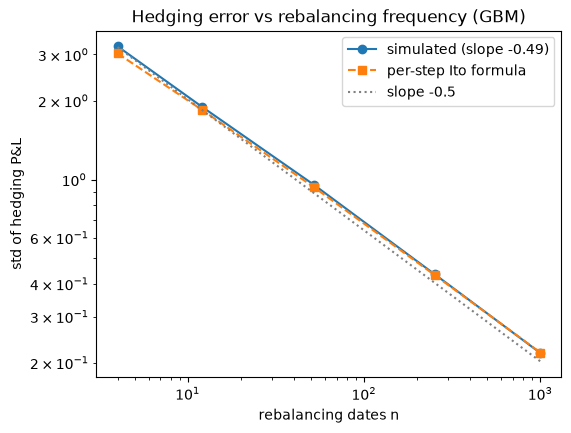

In [29]:
"""How the std of the hedging P&L shrinks with the number of rebalancing dates n.

Simulates exact GBM, hedges a short at-the-money call with BSM Deltas, and
fits log(std) = a + b log(N). Theory says b is close to -1/2. The std predicted
by the per-step Ito formula is shown alongside.
"""


S0, K, R, SIGMA, T = 100.0, 100.0, 0.05, 0.2, 1.0


STEP_COUNTS = [4, 12, 52, 252, 1000]


N_PATHS = 20_000


SEED = 42


def main() -> None:
    """Run the experiment: print the table and slope, save the table and the log-log figure."""
    rng = np.random.default_rng(SEED)
    rows = []
    for n_steps in STEP_COUNTS:
        paths = gbm_paths(S0, R, SIGMA, T, n_steps, N_PATHS, rng)
        pnl = hedge_pnl(paths, K, R, SIGMA, T)
        rows.append(
            {
                "N": n_steps,
                "mean_pnl": pnl.mean(),
                "std_pnl": pnl.std(),
                "predicted_std": predicted_pnl_std(paths, K, R, SIGMA, T),
            }
        )
    table = pd.DataFrame(rows)

    log_n = np.log(table["N"])
    slope, intercept = np.polyfit(log_n, np.log(table["std_pnl"]), 1)
    slope_tail = np.polyfit(log_n[2:], np.log(table["std_pnl"][2:]), 1)[0]
    pred_slope = np.polyfit(log_n, np.log(table["predicted_std"]), 1)[0]

    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(TABLES_DIR / "e1_rebalancing.csv", index=False)
    print(table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print(f"fitted slope (all N):         {slope:.3f}")
    print(f"fitted slope (N >= 52):       {slope_tail:.3f}")
    print(f"slope of predicted std:       {pred_slope:.3f}")

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.loglog(table["N"], table["std_pnl"], "o-", label=f"simulated (slope {slope:.2f})")
    ax.loglog(table["N"], table["predicted_std"], "s--", label="per-step Ito formula")
    ax.loglog(table["N"], np.exp(intercept) * table["N"] ** -0.5, ":", color="gray", label="slope -0.5")
    ax.set_xlabel("rebalancing dates n")
    ax.set_ylabel("std of hedging P&L")
    ax.set_title("Hedging error vs rebalancing frequency (GBM)")
    ax.legend()
    save_figure(fig, "e1_rebalancing")


main()

**Interpretation.** The fitted slope is $-0.487$ over all $n$ and $-0.500$ for $n \ge 52$, matching the quadratic-variation argument. The slope is slightly flatter at small $n$ because the formula is a small-$\Delta t$ expansion (at $n = 4$ the simulated standard deviation is about 6% above the prediction). In practice, halving the hedging risk takes four times as many rebalances, which sets up the cost trade-off in E5. Boyle and Emanuel (1980) and Bertsimas, Kogan and Lo (2000) study this error in more depth.

## Step 5: E2, wrong volatility

The stock has true volatility $\sigma$, but the seller prices and hedges with $\sigma_h$: $X(0) = C(0, S_0)$ and $\Delta = C_x$ are both computed at $\sigma_h$, so $C$ satisfies the BSM equation at $\sigma_h$ while $S$ moves with $\sigma$. The $dW$ terms cancel in $d\big(e^{-rt}(X - C)\big)$, and the BSM equation at $\sigma_h$ leaves

$$d\Big(e^{-rt}\big(X - C\big)\Big) = \tfrac12\big(\sigma_h^2 - \sigma^2\big)e^{-rt}S^2C_{xx}\,dt .$$

The seller's discounted terminal P&L is therefore (El Karoui, Jeanblanc and Shreve, 1998)

$$e^{-rT}\,\text{P\&L} = \tfrac12\big(\sigma_h^2 - \sigma^2\big)\int_0^Te^{-rt}S(t)^2C_{xx}(t, S(t))\,dt .$$

The dollar gamma $S^2C_{xx}$ is positive for a call, so the sign of the P&L is the sign of $\sigma_h - \sigma$: selling too dear locks in a gain and selling too cheap loses. The P&L is still random through the path of the dollar gamma. The code returns the P&L at time $T$, which is $e^{rT}$ times the right-hand side.

 sigma_h/sigma  mean_sim  mean_formula  std_error  std_sim  std_formula  pathwise_rmse
        0.5000   -3.8184       -3.8226     0.0144   2.0427       2.0286         0.3282
        0.7500   -1.9465       -1.9492     0.0063   0.8933       0.8644         0.2599
        1.0000    0.0018        0.0000     0.0015   0.2188       0.0000         0.2188
        1.2500    1.9790        1.9775     0.0049   0.6989       0.6626         0.1911
        1.5000    3.9673        3.9657     0.0085   1.2080       1.1849         0.1711


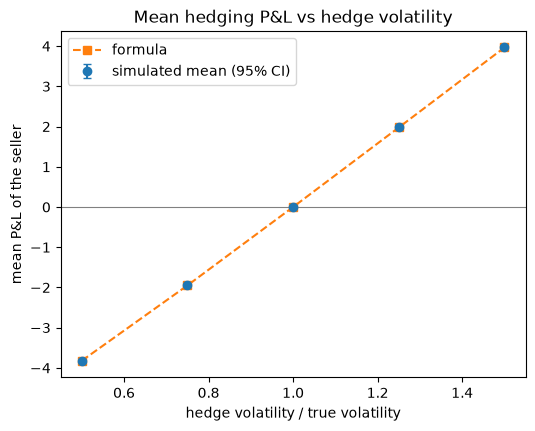

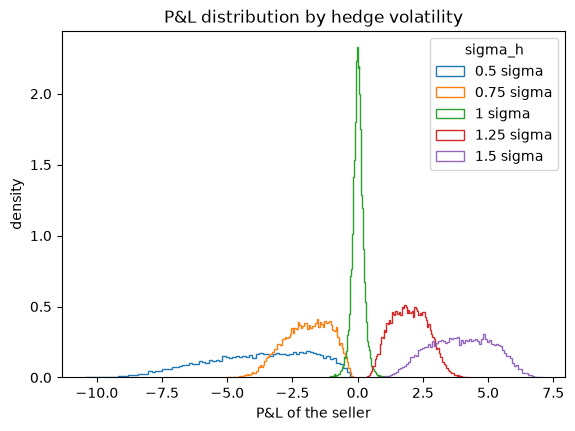

In [30]:
"""Hedging with the wrong volatility.

The stock follows GBM with true volatility sigma. The seller sells the call
and computes Deltas with sigma_h = ratio * sigma, with ratio from 0.5 to 1.5.
The simulated P&L is compared path by path with the El Karoui et al. formula.
"""


S0, K, R, SIGMA, T = 100.0, 100.0, 0.05, 0.2, 1.0


RATIOS = [0.5, 0.75, 1.0, 1.25, 1.5]


N_STEPS = 1000


N_PATHS = 20_000


SEED = 42


def main() -> None:
    """Run the experiment: print the comparison table, save the table and two figures."""
    rng = np.random.default_rng(SEED)
    paths = gbm_paths(S0, R, SIGMA, T, N_STEPS, N_PATHS, rng)

    rows, pnls = [], {}
    for ratio in RATIOS:
        hedge_vol = ratio * SIGMA
        pnl = hedge_pnl(paths, K, R, hedge_vol, T)
        formula = wrong_vol_pnl_formula(paths, K, R, SIGMA, hedge_vol, T)
        pnls[ratio] = pnl
        rows.append(
            {
                "sigma_h/sigma": ratio,
                "mean_sim": pnl.mean(),
                "mean_formula": formula.mean(),
                "std_error": pnl.std() / np.sqrt(N_PATHS),
                "std_sim": pnl.std(),
                "std_formula": formula.std(),
                "pathwise_rmse": np.sqrt(np.mean((pnl - formula) ** 2)),
            }
        )
    table = pd.DataFrame(rows)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(TABLES_DIR / "e2_wrong_vol.csv", index=False)
    print(table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.errorbar(table["sigma_h/sigma"], table["mean_sim"], yerr=1.96 * table["std_error"],
                fmt="o", capsize=3, label="simulated mean (95% CI)")
    ax.plot(table["sigma_h/sigma"], table["mean_formula"], "s--", label="formula")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel("hedge volatility / true volatility")
    ax.set_ylabel("mean P&L of the seller")
    ax.set_title("Mean hedging P&L vs hedge volatility")
    ax.legend()
    save_figure(fig, "e2_mean_pnl")

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for ratio in RATIOS:
        ax.hist(pnls[ratio], bins=80, histtype="step", density=True, label=f"{ratio:g} sigma")
    ax.set_xlabel("P&L of the seller")
    ax.set_ylabel("density")
    ax.set_title("P&L distribution by hedge volatility")
    ax.legend(title="sigma_h")
    save_figure(fig, "e2_distribution")


main()

**Interpretation.** The simulated mean P&L agrees with the formula to within about one standard error at every hedge volatility. Hedging at too high a volatility gives a gain and too low a loss, and the distribution is shifted and much wider than in the correctly specified case, mainly because the dollar-gamma integral varies across paths. A 25% volatility error moves the mean by about 2 on a premium of 10.45, far more than the discretisation error at $n = 1000$.

## Step 6: E3 and E4, wrong dynamics

BSM works because one traded asset spans the single source of risk $dW$. Under Heston there are two sources of risk but only the stock is traded, and under jumps the Delta cannot adjust in time. In both cases the market is incomplete: the option cannot be replicated, and a BSM Delta hedge leaves residual risk that does not vanish as rebalancing becomes continuous.

**Heston (E3).** The variance follows a CIR process. With the mapping $R \to V$, $\alpha_R \to a_V$, $\sigma_R \to \xi$,

$$dS = \alpha S\,dt + \sqrt{V}\,S\,dW_1, \qquad dV = (a_V - \beta V)\,dt + \xi\sqrt{V}\,dW_2, \qquad dW_1\,dW_2 = \rho\,dt,$$

with $E[V(t)] = V(0)e^{-\beta t} + \tfrac{a_V}{\beta}(1 - e^{-\beta t})$. The variance uses a full-truncation Euler scheme on a fine grid of 1,008 steps, and the hedge uses every $(1008/n)$-th date, so the simulation error does not change with the hedging frequency.

**Merton jumps (E4).** Compound Poisson jumps are added to GBM,

$$\frac{dS}{S} = (\alpha - \lambda\bar\kappa)\,dt + \sigma\,dW + (J - 1)\,dN, \qquad \ln J \sim N(m, \delta^2), \quad \bar\kappa = e^{m + \delta^2/2} - 1,$$

and sampled exactly. The compensator keeps $E[S(T)] = S_0e^{\alpha T}$.

**Setup.** The premium and Deltas always use BSM at $\sigma = 20\%$. For a fair comparison, Heston starts at $V(0) = a_V/\beta = 0.04$ and the Merton diffusion variance is reduced so that the total variance is also 0.04, so differences from GBM do not come from a different variance level. Parameters: $\beta = 2$, $a_V = 0.08$, $\lambda = 0.5$, $m = -0.1$, $\delta = 0.1$ for the main cases.

n = 252, 20000 paths
                    mean    std    skew  excess_kurtosis  VaR_5   ES_5
scenario                                                              
GBM               0.0018 0.4317 -0.1526           1.9218 0.6995 0.9872
xi=0.2, rho=-0.7 -0.0179 1.1019 -0.6238           1.6063 1.9511 2.7169
xi=0.4, rho=-0.7  0.1566 1.9517 -0.9280           2.1037 3.3494 4.8572
xi=0.6, rho=-0.7  0.4525 2.6473 -1.2752           3.2361 4.4614 6.6951
xi=0.4, rho=-0.9  0.1458 1.4810 -0.7491           0.6608 2.4959 3.4040
xi=0.4, rho=-0.5  0.1813 2.2415 -1.0242           2.7782 3.8367 5.7153
xi=0.4, rho=0.0   0.2996 2.5489 -1.0904           3.7060 4.2372 6.4429
xi=0.4, rho=0.5   0.5164 2.3591 -0.8230           2.5069 3.5230 5.4395
Monte Carlo standard errors with 20000 paths (bootstrap over the paths)
                   mean    std   skew  excess_kurtosis   ES_5
GBM              0.0028 0.0031 0.0464           0.2427 0.0133
xi=0.4, rho=-0.7 0.0140 0.0138 0.0387           0.2389 0.0656
   N  gbm_s

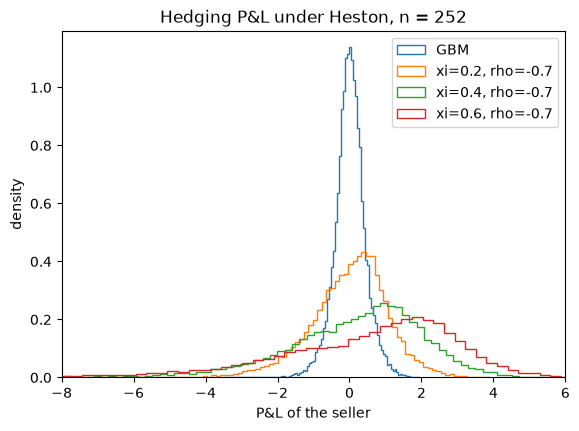

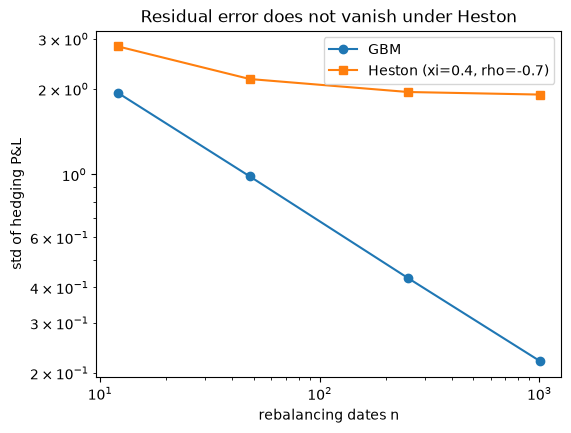

In [31]:
"""Delta hedging with BSM when the stock follows Heston stochastic volatility.

The Heston variance V(t) starts at V(0) = a_V / beta = sigma^2 = 0.04, so the average
variance matches the BSM volatility used for the premium and the Deltas (20%).
Two sweeps: vol-of-vol xi (rho fixed) and correlation rho (xi fixed). A GBM
run is the baseline, and a final sweep over N shows the error does not vanish
as rebalancing becomes more frequent. Heston paths are simulated on a fine grid
of 1008 Euler steps and the hedge uses every (1008 / N)-th date, so the
discretisation error of the simulation does not change with the hedging frequency.
"""


S0, K, R, SIGMA, T = 100.0, 100.0, 0.05, 0.2, 1.0


BETA, V_BAR = 2.0, SIGMA**2


A_V = BETA * V_BAR


N_STEPS = 252


FINE_STEPS = 1008


N_PATHS = 20_000


SEED = 42


XI_VALUES = [0.2, 0.4, 0.6]


RHO_VALUES = [-0.9, -0.5, 0.0, 0.5]


BASE_XI, BASE_RHO = 0.4, -0.7


STEP_COUNTS = [12, 48, 252, 1008]


def heston_pnl(xi: float, rho: float, n_steps: int) -> np.ndarray:
    """Hedging P&L of the short call on Heston paths, hedged with BSM at 20% on n_steps dates.

    The paths are simulated with FINE_STEPS Euler steps and subsampled to the
    n_steps hedging dates (n_steps must divide FINE_STEPS).
    """
    rng = np.random.default_rng(SEED)
    paths = heston_paths(S0, R, V_BAR, A_V, BETA, xi, rho, T, FINE_STEPS, N_PATHS, rng)
    return hedge_pnl(paths[:, :: FINE_STEPS // n_steps], K, R, SIGMA, T)


def main() -> None:
    """Run the experiment: print and save the summary table, save the figures."""
    rng = np.random.default_rng(SEED)
    gbm = hedge_pnl(gbm_paths(S0, R, SIGMA, T, N_STEPS, N_PATHS, rng), K, R, SIGMA, T)

    scenarios = {"GBM": gbm}
    for xi in XI_VALUES:
        scenarios[f"xi={xi}, rho={BASE_RHO}"] = heston_pnl(xi, BASE_RHO, N_STEPS)
    for rho in RHO_VALUES:
        scenarios[f"xi={BASE_XI}, rho={rho}"] = heston_pnl(BASE_XI, rho, N_STEPS)

    table = pd.DataFrame({name: pnl_summary(pnl) for name, pnl in scenarios.items()}).T
    table.index.name = "scenario"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(TABLES_DIR / "e3_heston.csv")
    print(f"n = {N_STEPS}, {N_PATHS} paths")
    print(table.to_string(float_format=lambda x: f"{x:.4f}"))
    errors = pd.DataFrame({name: bootstrap_standard_errors(scenarios[name])
                           for name in ("GBM", f"xi={BASE_XI}, rho={BASE_RHO}")}).T
    errors.to_csv(TABLES_DIR / "e3_mc_error.csv")
    print(f"Monte Carlo standard errors with {N_PATHS} paths (bootstrap over the paths)")
    print(errors.to_string(float_format=lambda x: f"{x:.4f}"))

    n_rows = [{"N": n, "gbm_std": hedge_pnl(gbm_paths(S0, R, SIGMA, T, n, N_PATHS, np.random.default_rng(SEED)),
                                            K, R, SIGMA, T).std(),
               "heston_std": heston_pnl(BASE_XI, BASE_RHO, n).std()} for n in STEP_COUNTS]
    n_table = pd.DataFrame(n_rows)
    n_table.to_csv(TABLES_DIR / "e3_heston_vs_n.csv", index=False)
    print(n_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name in ["GBM"] + [f"xi={xi}, rho={BASE_RHO}" for xi in XI_VALUES]:
        ax.hist(scenarios[name], bins=100, histtype="step", density=True, label=name)
    ax.set_xlim(-8, 6)
    ax.set_xlabel("P&L of the seller")
    ax.set_ylabel("density")
    ax.set_title(f"Hedging P&L under Heston, n = {N_STEPS}")
    ax.legend()
    save_figure(fig, "e3_distribution")

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.loglog(n_table["N"], n_table["gbm_std"], "o-", label="GBM")
    ax.loglog(n_table["N"], n_table["heston_std"], "s-", label=f"Heston (xi={BASE_XI}, rho={BASE_RHO})")
    ax.set_xlabel("rebalancing dates n")
    ax.set_ylabel("std of hedging P&L")
    ax.set_title("Residual error does not vanish under Heston")
    ax.legend()
    save_figure(fig, "e3_std_vs_n")


main()

**Interpretation (E3).** The standard deviation, VaR and ES grow with the vol-of-vol, and the error stays near 1.9 as $n$ grows instead of going to 0 (GBM falls from 1.94 to 0.22). The BSM Delta and gamma use a constant 20% while the true volatility is $\sqrt{V(t)}$, so the seller is in the wrong-volatility situation of E2 with a randomly varying volatility. Correlation changes the size of the residual: $\rho = -0.9$ gives the smallest standard deviation and $\rho = 0$ the largest, because with strong correlation the stock hedge captures part of the variance risk. The positive means for larger $\xi$ are consistent with a premium priced at constant volatility being too high. The Monte Carlo standard errors printed above show that the standard deviation is accurate to about 1%, while skewness ($\pm 0.04$ to $\pm 0.09$) and excess kurtosis ($\pm 0.24$ for Heston, $\pm 1.3$ for Merton) are much less precise, so small differences in those two are not interpreted.

## E4: Merton jumps

n = 252, 20000 paths, jump std = 0.1
                   mean    std    skew  excess_kurtosis  VaR_5    ES_5
scenario                                                              
GBM              0.0018 0.4317 -0.1526           1.9218 0.6995  0.9872
lam=0.25, m=-0.1 0.0615 1.5225 -4.3081          25.8100 2.6694  5.3894
lam=0.5, m=-0.1  0.1061 2.1825 -3.2859          15.3114 4.3897  7.3775
lam=1.0, m=-0.1  0.1838 3.0525 -2.0401           5.3678 6.2815  9.1644
lam=0.5, m=-0.05 0.0578 1.5586 -3.9300          24.4072 2.8882  5.2968
lam=0.5, m=-0.2  0.2723 4.2789 -1.9250           4.0002 9.1739 12.5356
Monte Carlo standard errors with 20000 paths (bootstrap over the paths)
                  mean    std   skew  excess_kurtosis   ES_5
GBM             0.0028 0.0031 0.0464           0.2427 0.0133
lam=0.5, m=-0.1 0.0148 0.0314 0.0933           1.2611 0.1272
   N  gbm_std  merton_std
  12   1.9419      2.7762
  52   0.9523      2.2956
 252   0.4317      2.1825
1000   0.2188      2.1750


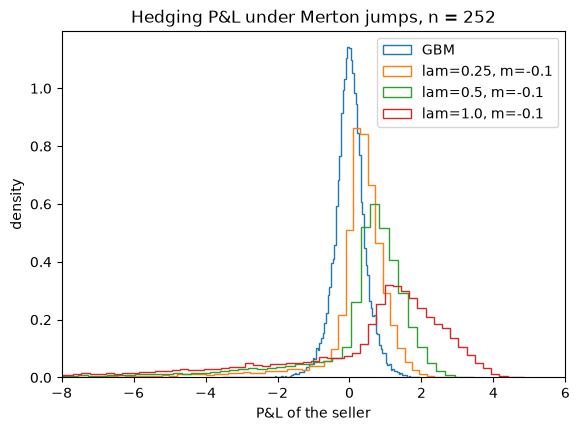

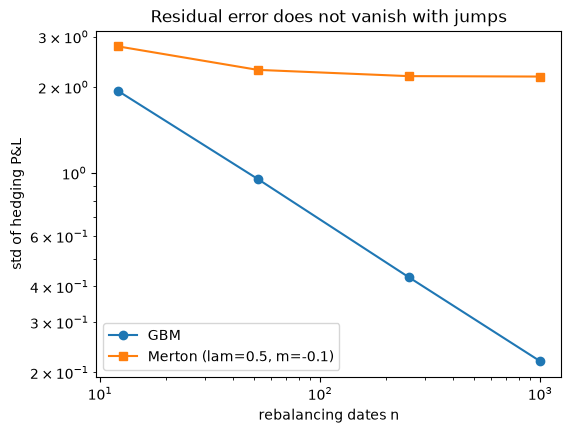

In [32]:
"""Delta hedging with BSM when the stock follows a Merton jump-diffusion.

The diffusion volatility is lowered as jumps are added so that the total
variance sigma_d^2 + lam (m^2 + delta^2) always equals 0.04, the BSM variance
used for the premium and the Deltas (20% volatility). The comparison with GBM
then isolates the effect of jumps on the shape of the P&L distribution, not on
its variance level. Two sweeps: jump intensity (size fixed) and jump size
(intensity fixed). A final sweep over N shows the error does not vanish.
"""


S0, K, R, SIGMA, T = 100.0, 100.0, 0.05, 0.2, 1.0


N_STEPS = 252


N_PATHS = 20_000


SEED = 42


JUMP_STD = 0.1


RATES = [0.25, 0.5, 1.0]


BASE_RATE, SIZES = 0.5, [-0.05, -0.1, -0.2]


BASE_SIZE = -0.1


STEP_COUNTS = [12, 52, 252, 1000]


def merton_pnl(jump_rate: float, jump_mean: float, n_steps: int) -> np.ndarray:
    """Hedging P&L of the short call on variance-matched Merton paths."""
    diffusion_var = SIGMA**2 - jump_rate * (jump_mean**2 + JUMP_STD**2)
    rng = np.random.default_rng(SEED)
    paths = merton_paths(S0, R, np.sqrt(diffusion_var), jump_rate, jump_mean, JUMP_STD,
                         T, n_steps, N_PATHS, rng)
    return hedge_pnl(paths, K, R, SIGMA, T)


def gbm_pnl(n_steps: int) -> np.ndarray:
    """Hedging P&L of the short call under GBM (baseline)."""
    paths = gbm_paths(S0, R, SIGMA, T, n_steps, N_PATHS, np.random.default_rng(SEED))
    return hedge_pnl(paths, K, R, SIGMA, T)


def main() -> None:
    """Run the experiment: print and save the summary table, save the figures."""
    scenarios = {"GBM": gbm_pnl(N_STEPS)}
    for rate in RATES:
        scenarios[f"lam={rate}, m={BASE_SIZE}"] = merton_pnl(rate, BASE_SIZE, N_STEPS)
    for size in SIZES:
        if size != BASE_SIZE:
            scenarios[f"lam={BASE_RATE}, m={size}"] = merton_pnl(BASE_RATE, size, N_STEPS)

    table = pd.DataFrame({name: pnl_summary(pnl) for name, pnl in scenarios.items()}).T
    table.index.name = "scenario"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(TABLES_DIR / "e4_jumps.csv")
    print(f"n = {N_STEPS}, {N_PATHS} paths, jump std = {JUMP_STD}")
    print(table.to_string(float_format=lambda x: f"{x:.4f}"))
    errors = pd.DataFrame({name: bootstrap_standard_errors(scenarios[name])
                           for name in ("GBM", f"lam={BASE_RATE}, m={BASE_SIZE}")}).T
    errors.to_csv(TABLES_DIR / "e4_mc_error.csv")
    print(f"Monte Carlo standard errors with {N_PATHS} paths (bootstrap over the paths)")
    print(errors.to_string(float_format=lambda x: f"{x:.4f}"))

    n_table = pd.DataFrame(
        [{"N": n, "gbm_std": gbm_pnl(n).std(), "merton_std": merton_pnl(BASE_RATE, BASE_SIZE, n).std()}
         for n in STEP_COUNTS]
    )
    n_table.to_csv(TABLES_DIR / "e4_jumps_vs_n.csv", index=False)
    print(n_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name in ["GBM"] + [f"lam={rate}, m={BASE_SIZE}" for rate in RATES]:
        ax.hist(scenarios[name], bins=120, histtype="step", density=True, label=name)
    ax.set_xlim(-8, 6)
    ax.set_xlabel("P&L of the seller")
    ax.set_ylabel("density")
    ax.set_title(f"Hedging P&L under Merton jumps, n = {N_STEPS}")
    ax.legend()
    save_figure(fig, "e4_distribution")

    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.loglog(n_table["N"], n_table["gbm_std"], "o-", label="GBM")
    ax.loglog(n_table["N"], n_table["merton_std"], "s-", label=f"Merton (lam={BASE_RATE}, m={BASE_SIZE})")
    ax.set_xlabel("rebalancing dates n")
    ax.set_ylabel("std of hedging P&L")
    ax.set_title("Residual error does not vanish with jumps")
    ax.legend()
    save_figure(fig, "e4_std_vs_n")


main()

**Interpretation (E4).** The seller is short gamma, so a large move in either direction loses money and the Delta cannot be adjusted in time. Most paths have no jump and a small gain, and a few have a large loss, which gives a long left tail, strongly negative skew, high kurtosis and an ES far above the VaR. The error levels off at about 2.2 as $n$ grows, so more frequent hedging cannot remove jump risk. Larger jumps make it worse (VaR 9.17 at $m = -0.2$). The comparison is variance-matched, so these differences come from the shape of the distribution. The parameters are illustrative, not calibrated.

## Step 7: E5, transaction costs

Leland (1985) extends the BSM hedging argument by a cost on every trade. The cost rate $k$ is the round-trip proportional cost, so each one-way trade pays $\tfrac{k}{2}\,|\text{shares traded}|\,S$.

**Cost against risk.** Per step the hedge ratio changes by about $C_{xx}\,dS$ with $dS \sim S\sigma\sqrt{\Delta t}\,Z$, so the expected absolute trade is $C_{xx}S\sigma\sqrt{\Delta t}\sqrt{2/\pi}$ and

$$\text{expected total cost} \approx \tfrac{k}{2}\sqrt{\tfrac2\pi}\,\frac{\sigma}{\sqrt{\Delta t}}\int_0^TS^2C_{xx}\,dt .$$

Cost grows like $\sqrt n$ while the hedging risk falls like $1/\sqrt n$, so there is an interior optimum.

**Leland's adjusted volatility.** The extra cost acts like the gamma term of E2 with

$$\hat\sigma^2 = \sigma^2\Big(1 + \sqrt{\tfrac2\pi}\,\frac{k}{\sigma\sqrt{\Delta t}}\Big),$$

so pricing and hedging at $\hat\sigma$ covers the expected cost. The correction is of order $k/\sqrt{\Delta t}$, which is why frequent trading is expensive.

**Optimal $n$.** Risk is measured by the RMSE of the net P&L about zero, $\mathrm{RMSE}^2 = \text{bias}^2 + \text{variance}$, with bias equal to the expected cost. With std $= s/\sqrt n$ and cost $= a\sqrt n$ ($a$ proportional to $k$),

$$\mathrm{RMSE}^2 = a^2n + \frac{s^2}{n}, \qquad n^* = \frac{s}{a}.$$

Other criteria (a mean-variance objective with another risk aversion, or ES) give a different $n^*$. The simulated optimum is searched over the grid $n = 12, 26, 52, 78, 104, 156, 208, 252, 378, 504, 756, 1000$.

     k    N  mean_cost  leland_cost  mean_pnl  std_pnl   rmse  pred_rmse
0.0010   12     0.0819       0.0804   -0.0893   1.9471 1.9491     1.8485
0.0025   12     0.2049       0.2010   -0.2165   1.9552 1.9671     1.8576
0.0050   12     0.4097       0.4020   -0.4286   1.9693 2.0154     1.8900
0.0100   12     0.8195       0.8039   -0.8528   2.0002 2.1744     2.0141
0.0010   52     0.1421       0.1410   -0.1484   0.9585 0.9699     0.9468
0.0025   52     0.3552       0.3525   -0.3681   0.9712 1.0386     1.0004
0.0050   52     0.7104       0.7051   -0.7343   1.0007 1.2412     1.1720
0.0100   52     1.4209       1.4102   -1.4667   1.0879 1.8261     1.6926
0.0010  252     0.2746       0.2739   -0.2805   0.4460 0.5269     0.5119
0.0025  252     0.6864       0.6848   -0.7040   0.5017 0.8645     0.8099
0.0050  252     1.3729       1.3696   -1.4098   0.6560 1.5550     1.4363
0.0100  252     2.7458       2.7392   -2.8215   1.0618 3.0147     2.7731
0.0010 1000     0.5159       0.5156   -0.5280   0.2

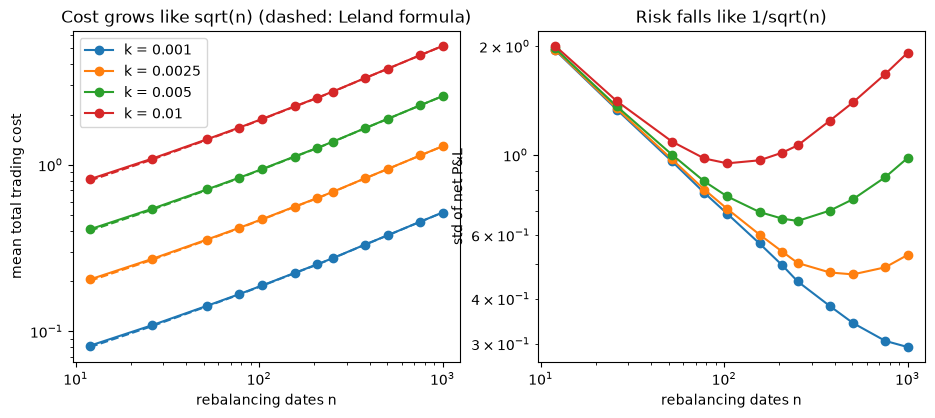

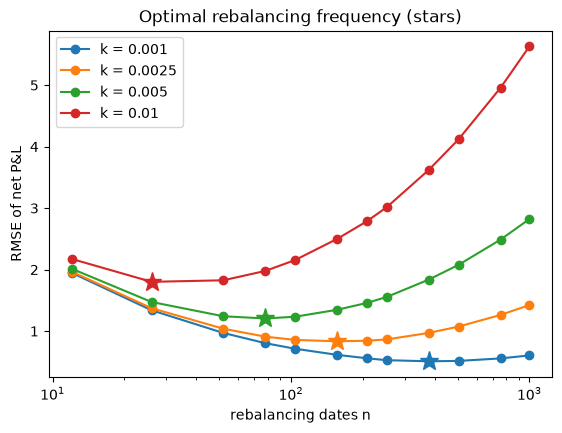

In [33]:
"""Proportional transaction costs, the optimal rebalancing frequency and Leland's scaling.

GBM paths, short at-the-money call hedged with BSM Deltas (20%) on N dates, for
several round-trip cost rates k. Three things are measured:
  1. total trading cost vs N, against the Leland expected-cost formula;
  2. the std of the net P&L vs N;
  3. the RMSE of the net P&L (bias^2 + variance) vs N. Its minimum over N is the
     optimal rebalancing frequency, compared with the closed-form N* = s / a that
     follows from std ~ s / sqrt(n) and cost ~ a sqrt(n).
A last table tests Leland's claim that pricing and hedging at sigma_hat removes
the cost bias.
"""


S0, K, R, SIGMA, T = 100.0, 100.0, 0.05, 0.2, 1.0


COST_RATES = [0.001, 0.0025, 0.005, 0.01]


STEP_COUNTS = [12, 26, 52, 78, 104, 156, 208, 252, 378, 504, 756, 1000]


LELAND_COST_RATE = 0.005


LELAND_STEP_COUNTS = [26, 52, 252]


N_PATHS = 20_000


SEED = 42


def main() -> None:
    """Run the experiment: print and save the tables, save the figures."""
    rows = []
    closed_form = {}
    for n_steps in STEP_COUNTS:
        paths = gbm_paths(S0, R, SIGMA, T, n_steps, N_PATHS, np.random.default_rng(SEED))
        pred_std = predicted_pnl_std(paths, K, R, SIGMA, T)
        for k in COST_RATES:
            pnl, cost = hedge_pnl_and_cost(paths, K, R, SIGMA, T, cost_rate=k)
            pred_cost = leland_expected_cost(paths, K, R, SIGMA, k, T)
            rows.append(
                {
                    "k": k,
                    "N": n_steps,
                    "mean_cost": cost.mean(),
                    "leland_cost": pred_cost,
                    "mean_pnl": pnl.mean(),
                    "std_pnl": pnl.std(),
                    "rmse": np.sqrt(np.mean(pnl**2)),
                    "pred_rmse": np.hypot(pred_cost, pred_std),
                }
            )
            if n_steps == 252:
                closed_form[k] = (pred_std * np.sqrt(n_steps)) / (pred_cost / np.sqrt(n_steps))
    table = pd.DataFrame(rows)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(TABLES_DIR / "e5_costs.csv", index=False)
    print(table[table["N"].isin([12, 52, 252, 1000])].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    optimum = pd.DataFrame(
        [
            {
                "k": k,
                "N_star_sim": int(g.loc[g["rmse"].idxmin(), "N"]),
                "N_star_leland_model": int(g.loc[g["pred_rmse"].idxmin(), "N"]),
                "N_star_closed_form": closed_form[k],
                "min_rmse": g["rmse"].min(),
                "leland_Le_at_N_star": np.sqrt(2 / np.pi) * k / (SIGMA * np.sqrt(T / g.loc[g["rmse"].idxmin(), "N"])),
            }
            for k, g in table.groupby("k")
        ]
    )
    optimum.to_csv(TABLES_DIR / "e5_optimal_n.csv", index=False)
    slope = np.polyfit(np.log(optimum["k"]), np.log(optimum["N_star_closed_form"]), 1)[0]
    print(optimum.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print(f"log-log slope of closed-form N* against k: {slope:.3f}")

    leland_rows = []
    for n_steps in LELAND_STEP_COUNTS:
        paths = gbm_paths(S0, R, SIGMA, T, n_steps, N_PATHS, np.random.default_rng(SEED))
        hat = leland_vol(SIGMA, LELAND_COST_RATE, T / n_steps)
        for label, sigma_used in [("sigma", SIGMA), ("sigma_hat", hat)]:
            pnl, _ = hedge_pnl_and_cost(paths, K, R, sigma_used, T, cost_rate=LELAND_COST_RATE)
            leland_rows.append({"N": n_steps, "premium_and_hedge_vol": label, "vol": sigma_used,
                                "mean_pnl": pnl.mean(), "std_pnl": pnl.std()})
    leland_table = pd.DataFrame(leland_rows)
    leland_table.to_csv(TABLES_DIR / "e5_leland.csv", index=False)
    print(f"Leland check, k = {LELAND_COST_RATE}")
    print(leland_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    for k, g in table.groupby("k"):
        line, = axes[0].loglog(g["N"], g["mean_cost"], "o-", label=f"k = {k}")
        axes[0].loglog(g["N"], g["leland_cost"], "--", color=line.get_color())
        axes[1].loglog(g["N"], g["std_pnl"], "o-", label=f"k = {k}")
    axes[0].set(xlabel="rebalancing dates n", ylabel="mean total trading cost",
                title="Cost grows like sqrt(n) (dashed: Leland formula)")
    axes[1].set(xlabel="rebalancing dates n", ylabel="std of net P&L", title="Risk falls like 1/sqrt(n)")
    axes[0].legend()
    save_figure(fig, "e5_cost_and_risk")

    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for k, g in table.groupby("k"):
        line, = ax.semilogx(g["N"], g["rmse"], "o-", label=f"k = {k}")
        best = g.loc[g["rmse"].idxmin()]
        ax.plot(best["N"], best["rmse"], "*", ms=14, color=line.get_color())
    ax.set(xlabel="rebalancing dates n", ylabel="RMSE of net P&L", title="Optimal rebalancing frequency (stars)")
    ax.legend()
    save_figure(fig, "e5_optimal_n")


main()

**Interpretation.** The simulated cost matches Leland's formula to within 2% in every row, and the standard deviation of the net P&L stops falling at large $n$ because the random cost adds variance. The simulated optimal $n$ is 378, 156, 78 and 26 for $k = 0.001$, $0.0025$, $0.005$ and $0.01$, against 398, 159, 80 and 40 from the closed form. The two agree to a few percent for $k \le 0.005$. At $k = 0.01$ the RMSE is flat between $n = 26$ and $52$ and the grid is coarse, so the gap to 40 is within the resolution. The optimum falls roughly like $1/k$ for small $k$ (from $k = 0.005$ to $0.01$ it falls by a factor of 3, not 2). Pricing at $\hat\sigma$ removes the $n$-dependent bias: the mean P&L becomes a constant $-0.16$ for $n = 26, 52, 252$, which is the initial purchase cost $\tfrac{k}{2}\Delta(0)S_0$ that Leland's formula does not cover. With $k = 0.5\%$, weekly to daily hedging is already too frequent, and the best is about $n = 78$ under this criterion.

## Step 8: E6, moneyness and maturity

The per-step error $\tfrac12C_{xx}\sigma^2S^2\big[(\Delta W)^2 - \Delta t\big]$ is proportional to the dollar gamma $S^2C_{xx}$, so the hedging error is large where and when the option has high gamma, which is near the strike and near expiry. For an at-the-money option $S^2C_{xx}$ grows like $1/\sqrt\tau$ as $\tau \to 0$, so late steps contribute most, while a deep in- or out-of-the-money option has small gamma and a small error in absolute terms. Hedging here is weekly ($\Delta t = 1/52$) under GBM, and the cell below sweeps the strike and the maturity.

Strike sweep, T = 1, weekly hedging
       K      T  N  premium  dollar_gamma_0  std_sim  std_pred  std_over_premium
 80.0000 1.0000 52  24.5888         68.1360   0.4650    0.4495            0.0189
 90.0000 1.0000 52  16.6994        135.8129   0.7454    0.7285            0.0446
100.0000 1.0000 52  10.4506        187.6202   0.9523    0.9362            0.0911
110.0000 1.0000 52   6.0401        197.8802   1.0173    0.9949            0.1684
120.0000 1.0000 52   3.2475        170.3692   0.9547    0.9335            0.2940
Maturity sweep, K = 100, weekly hedging
       K      T   N  premium  dollar_gamma_0  std_sim  std_pred  std_over_premium
100.0000 0.1000   5   2.7737        626.9314   0.9372    0.8745            0.3379
100.0000 0.2500  13   4.6150        392.8800   0.9442    0.8956            0.2046
100.0000 0.5000  26   6.8887        273.5866   0.9430    0.9173            0.1369
100.0000 1.0000  52  10.4506        187.6202   0.9523    0.9362            0.0911
100.0000 2.0000 104  16.1268

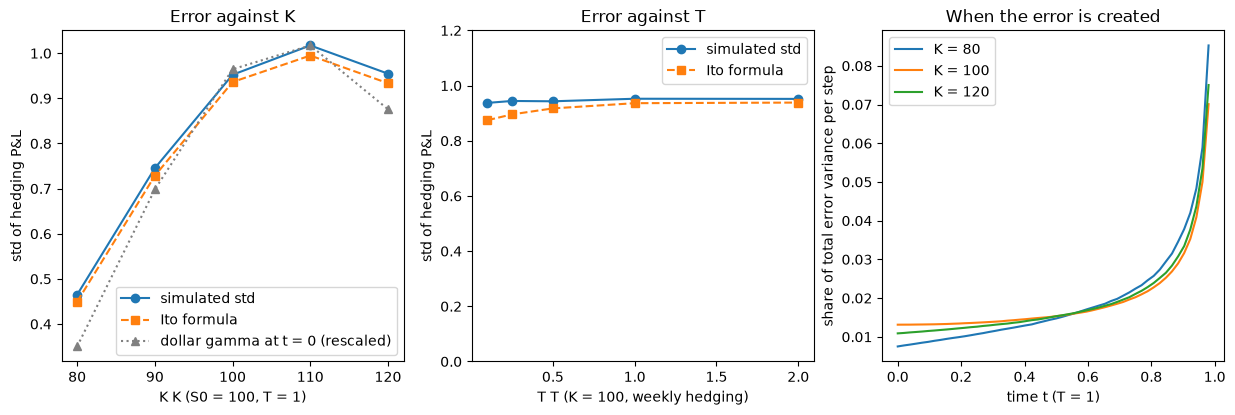

In [34]:
"""Hedging error against K and T, and its link to the gamma profile.

GBM paths, short call hedged weekly (dt = 1/52, so N = 52 T) with BSM Deltas at
the true volatility. The simulated std of the P&L is compared with the std from
the per-step Ito formula, which is driven by the dollar gamma S^2 Gamma. A third
panel shows when in the option's life the error variance is created.
"""


S0, R, SIGMA = 100.0, 0.05, 0.2


STRIKES = [80.0, 90.0, 100.0, 110.0, 120.0]


MATURITIES = [0.1, 0.25, 0.5, 1.0, 2.0]


BASE_STRIKE, BASE_MATURITY = 100.0, 1.0


STEPS_PER_YEAR = 52


N_PATHS = 20_000


SEED = 42


def run_case(K: float, T: float) -> tuple[dict, np.ndarray]:
    """Simulate one (K, T) case; return its table row and variance profile."""
    n_steps = round(STEPS_PER_YEAR * T)
    paths = gbm_paths(S0, R, SIGMA, T, n_steps, N_PATHS, np.random.default_rng(SEED))
    pnl = hedge_pnl(paths, K, R, SIGMA, T)
    premium = float(bs.call_price(S0, K, R, SIGMA, T))
    row = {
        "K": K,
        "T": T,
        "N": n_steps,
        "premium": premium,
        "dollar_gamma_0": S0**2 * float(bs.gamma(S0, K, R, SIGMA, T)),
        "std_sim": pnl.std(),
        "std_pred": predicted_pnl_std(paths, K, R, SIGMA, T),
        "std_over_premium": pnl.std() / premium,
    }
    return row, error_variance_profile(paths, K, R, SIGMA, T)


def main() -> None:
    """Run the experiment: print and save the tables, save the three-panel figure."""
    strike_rows = [run_case(k, BASE_MATURITY)[0] for k in STRIKES]
    maturity_rows = [run_case(BASE_STRIKE, t)[0] for t in MATURITIES]
    strike_table, maturity_table = pd.DataFrame(strike_rows), pd.DataFrame(maturity_rows)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    strike_table.to_csv(TABLES_DIR / "e6_strike.csv", index=False)
    maturity_table.to_csv(TABLES_DIR / "e6_maturity.csv", index=False)
    fmt = lambda x: f"{x:.4f}"
    print("Strike sweep, T = 1, weekly hedging")
    print(strike_table.to_string(index=False, float_format=fmt))
    print("Maturity sweep, K = 100, weekly hedging")
    print(maturity_table.to_string(index=False, float_format=fmt))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
    ax = axes[0]
    ax.plot(strike_table["K"], strike_table["std_sim"], "o-", label="simulated std")
    ax.plot(strike_table["K"], strike_table["std_pred"], "s--", label="Ito formula")
    scale = strike_table["std_sim"].max() / strike_table["dollar_gamma_0"].max()
    ax.plot(strike_table["K"], scale * strike_table["dollar_gamma_0"], "^:", color="gray",
            label="dollar gamma at t = 0 (rescaled)")
    ax.set(xlabel="K K (S0 = 100, T = 1)", ylabel="std of hedging P&L", title="Error against K")
    ax.legend()

    ax = axes[1]
    ax.plot(maturity_table["T"], maturity_table["std_sim"], "o-", label="simulated std")
    ax.plot(maturity_table["T"], maturity_table["std_pred"], "s--", label="Ito formula")
    ax.set(xlabel="T T (K = 100, weekly hedging)", ylabel="std of hedging P&L", title="Error against T")
    ax.set_ylim(0, 1.2)
    ax.legend()

    ax = axes[2]
    for K in (80.0, 100.0, 120.0):
        profile = run_case(K, BASE_MATURITY)[1]
        ax.plot(np.arange(len(profile)) / STEPS_PER_YEAR, profile / profile.sum(), label=f"K = {K:g}")
    ax.set(xlabel="time t (T = 1)", ylabel="share of total error variance per step",
           title="When the error is created")
    ax.legend()
    save_figure(fig, "e6_moneyness_maturity")


main()

**Interpretation.**
- **Strike.** The standard deviation rises from 0.47 at $K = 80$ to a peak of 1.02 near $K = 110$ and falls again, following the dollar-gamma profile. The second-order Itô formula tracks the simulation at all strikes, about 2 to 3% low, because it drops higher-order terms.
- **Relative to the premium,** the error grows steadily with the strike, from 2% at $K = 80$ to 29% at $K = 120$, since out-of-the-money options are cheap.
- **Maturity.** At fixed weekly $\Delta t$ the standard deviation is nearly flat (0.94 to 0.95 from $T = 0.1$ to $2$), but relative to the premium short-dated options are much harder to hedge (34% at $T = 0.1$ against 6% at $T = 2$). The Itô formula is 7% low at $T = 0.1$, where $n = 5$ steps are too coarse for a second-order expansion.
- **Timing.** The error is created mostly near expiry (right panel): for $K = 100$, $T = 1$, the last weekly step carries about 7% of the total error variance and the first about 1.3%.

## Step 9: E7, backtest on real listed option prices

The simulations assume a model for the stock. The backtest asks how a BSM Delta hedge performs when both the stock path and the option price come from the market. By the earlier steps, the error is the discretisation error of E1 plus the wrong-volatility term of E2, where the true volatility is whatever NIFTY realised over the option's life.

**Realised and implied volatility.** The realised volatility over the option's life $[T_1, T_2]$ is

$$\hat\sigma = \sqrt{\frac{1}{T_2 - T_1}\sum_{i=0}^{n-1}\Big[\ln\frac{S(t_{i+1})}{S(t_i)}\Big]^2},$$

which estimates $\sigma$ because $\sum(\Delta W)^2 \to T_2 - T_1$. The implied volatility is the $\sigma$ for which $\text{BSM}(\tau, x, K, r, \sigma)$ equals the listed price. The listed call is priced and hedged at its implied volatility (the role of $\sigma_h$ in E2), and the realised volatility plays the role of the true $\sigma$.

**Method.**
- An entry date is used when a NIFTY expiry falls exactly 20 trading days later ($T = 20/252$), which gives the same 20-step grid as the simulations.
- The traded call with the strike nearest the NIFTY close, and within 1% of it, is sold at its listed close. The 1% filter matters: without it, 23 of 395 windows had a strike more than 1% from spot (one was 44% away) and distorted the result. That leaves 372 windows.
- The hedge uses the call's own implied volatility ($r = 6\%$, no dividends) and is rebalanced daily (20 steps) or weekly (4 steps) along the real index path. P&L is divided by the premium.
- The simulations use $S_0 = K = 100$, $\alpha = r = 6\%$, $T = 20/252$ and $\sigma = 14.77\%$, the sample's mean implied volatility, with 20 daily steps. Heston uses $\beta = 2$, $a_V = \beta\sigma^2$, $V(0) = \sigma^2$, $\xi = 0.4$, $\rho = -0.7$. Merton is not simulated, because in a 20-day window almost every path has no jump while a few lose far more than the premium.

**Gamma-weighted formula.** Each real window is hedged at its own implied volatility, so windows differ in the gap between implied and realised volatility, which adds spread and skew that the simulations lack. The window-average E2 formula removes only part of this. The pathwise version weights each day's squared return by that day's dollar gamma:

$$\text{P\&L} \approx \tfrac12\sum_i e^{r(T-t_i)}\,S(t_i)^2C_{xx}(t_i,S(t_i))\Big[\sigma_h^2\Delta t_i - \Big(\ln\frac{S(t_{i+1})}{S(t_i)}\Big)^2\Big].$$

The window-average version replaces every squared return by $\hat\sigma^2\Delta t_i$, which is accurate only when the variance is spread evenly over the window. The entry of 26 February 2020 shows why this fails: the index crashed while the option was far out of the money, so gamma was near zero on the crash days. The window-average formula predicts a loss of 3.6 times the premium, the actual loss was 0.44 times, and the gamma-weighted formula predicts 0.56.

NIFTY days: 2921; windows: 372 from 2015-01-28 to 2026-10-09
strike within 0.98% of spot (median 0.09%); median premium 352.9 index points
mean implied vol 0.1477, mean realised vol 0.1350; implied above realised in 68.3% of windows
Wrong-volatility formula (realised vol per window): mean 22.98 vs backtest 23.61 points; correlation 0.868
simulations: sigma = 0.1477 (mean implied vol), alpha = r = 0.06, T = 20/252, S0 = K = 100, 20 daily steps, 20000 paths
P&L / premium
                mean   std   skew  excess_kurtosis  VaR_5  ES_5
sample                                                         
listed daily   0.058 0.247 -1.100            2.459  0.449 0.625
listed weekly  0.008 0.398 -1.569            5.830  0.640 1.099
GBM daily      0.001 0.167 -0.374            1.705  0.277 0.392
GBM weekly    -0.001 0.352 -0.594            1.282  0.603 0.850
Heston daily   0.007 0.226 -0.843            2.773  0.379 0.572
Heston weekly  0.004 0.387 -1.032            2.843  0.684 1.008
Pathwise (gamm

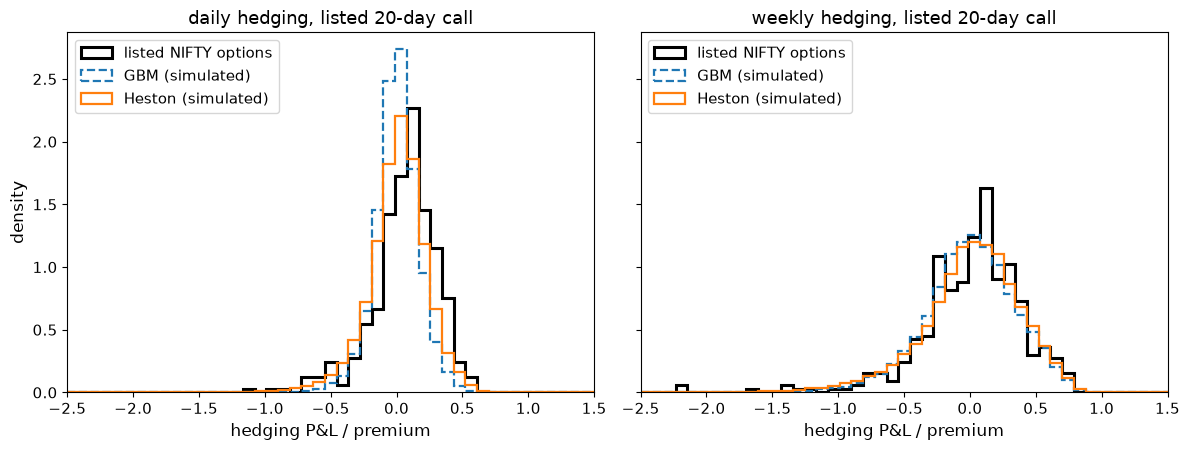

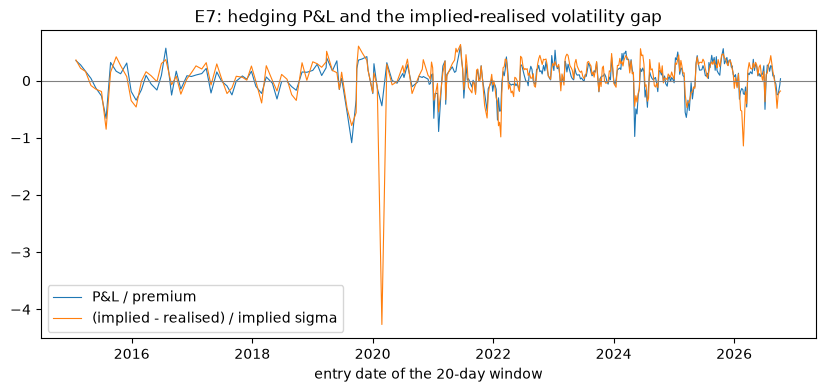

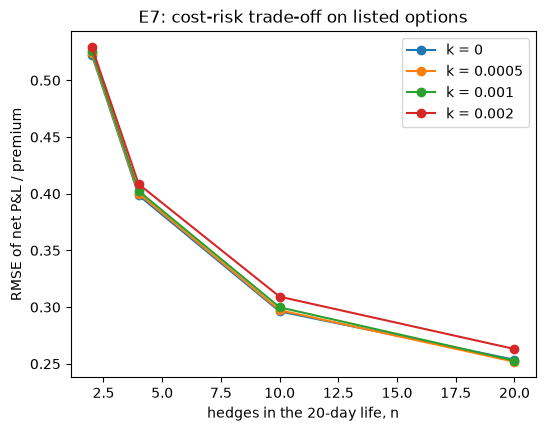

In [35]:
"""Backtest of daily and weekly delta hedging on real listed NIFTY call options.

A short NIFTY call is sold at its NSE closing price on every day when an expiry falls exactly
20 trading days later and hedged with BSM Deltas at its own implied volatility along the real
NIFTY 50 path until expiry. The P&L is divided by the premium and compared with GBM and Heston
simulations at the sample's average implied volatility, with the wrong-volatility formula, and
with the gamma-weighted pathwise formula.
"""


N_DAYS = 20


R = 0.06


HEDGE_EVERY = {"daily": 1, "weekly": 5}


FIRST_DATE = "2015-01-01"


MAX_STRIKE_GAP = 0.01


LARGE_MOVE = 0.04


SENSITIVITY_GAPS = [0.005, 0.01, 0.02]


BLOCK_LENGTHS = [3, 5, 10]


COST_RATES = [0.0005, 0.001, 0.002]


COST_STEPS = [1, 2, 5, 10]


RATE_GRID = [(0.04, 0.0), (0.06, 0.0), (0.08, 0.0), (0.04, 0.013), (0.06, 0.013), (0.08, 0.013)]


N_PATHS = 20_000


SEED = 42


BETA, XI, RHO = 2.0, 0.4, -0.7


def simulated_paths(sigma: float) -> dict[str, np.ndarray]:
    """Daily paths of the 20-day simulations, by model (GBM and Heston).

    Both start at S_0 = K = 100, with alpha = r, T = 20/252 and total variance
    sigma^2 (the sample's mean implied volatility). Heston uses the settings of
    the Heston experiment: beta = 2, a_V = beta sigma^2, V(0) = sigma^2, xi = 0.4, rho = -0.7. The
    Merton jump parameters of the jump experiment were chosen for one-year options and do not
    carry over to a 20-day window, so Merton is not simulated here.
    """
    T = N_DAYS / TRADING_DAYS
    generators = {
        "GBM": lambda rng: gbm_paths(100.0, R, sigma, T, N_DAYS, N_PATHS, rng),
        "Heston": lambda rng: heston_paths(100.0, R, sigma**2, BETA * sigma**2, BETA, XI, RHO, T, N_DAYS, N_PATHS, rng),
    }
    return {name: generate(np.random.default_rng(SEED)) for name, generate in generators.items()}


def simulated_rel_pnl(sigma: float, paths: dict[str, np.ndarray]) -> dict[str, dict[str, np.ndarray]]:
    """P&L / premium of the hedge (premium and Deltas at `sigma`) on the simulated paths, by model and frequency.

    Paths are daily; weekly hedging takes every 5th date.
    """
    T = N_DAYS / TRADING_DAYS
    premium = float(bs.call_price(100.0, 100.0, R, sigma, T))
    return {
        name: {freq: hedge_pnl(p[:, ::step], 100.0, R, sigma, T) / premium for freq, step in HEDGE_EVERY.items()}
        for name, p in paths.items()
    }


def e2_formula_pnl(data: pd.DataFrame, listed: pd.DataFrame, step: int) -> np.ndarray:
    """The wrong-volatility formula (P&L at T) for each listed window, with its realised vol as sigma and its implied vol as sigma_h."""
    T = N_DAYS / TRADING_DAYS
    windows = make_windows(data["nifty"].to_numpy(), N_DAYS)[data.index.get_indexer(listed.index)]
    return np.array([
        wrong_vol_pnl_formula(w[None, ::step], K, R, rv, iv, T)[0]
        for w, K, rv, iv in zip(windows, listed["strike"], listed["realised_vol"], listed["implied_vol"])
    ])


def pathwise_table(data: pd.DataFrame, results: dict[str, pd.DataFrame], sigma: float,
                   paths: dict[str, np.ndarray]) -> pd.DataFrame:
    """How well the pathwise (gamma-weighted) formula explains the P&L, for the listed windows and the simulations.

    For every sample the table gives the correlation between the P&L and the
    formula and the standard deviation (and skewness, kurtosis) of the residual
    (P&L - formula) / premium. The listed windows are also split by whether the
    window contains a daily move larger than LARGE_MOVE (4% in log terms), because
    the second-order formula fails on such days.
    """
    T = N_DAYS / TRADING_DAYS
    premium_sim = float(bs.call_price(100.0, 100.0, R, sigma, T))
    all_windows = make_windows(data["nifty"].to_numpy(), N_DAYS)
    rows = []

    def add_row(freq, label, pnl, formula, residual, mean_in_points):
        rows.append({"frequency": freq, "sample": label, "windows": len(pnl),
                     "corr_with_pnl": float(np.corrcoef(pnl, formula)[0, 1]),
                     "mean_pnl": float(np.mean(pnl)) if mean_in_points else np.nan,
                     "mean_formula": float(np.mean(formula)) if mean_in_points else np.nan,
                     "resid_std": float(np.std(residual)), "resid_skew": float(skew(residual)),
                     "resid_excess_kurtosis": float(kurtosis(residual))})

    for freq, step in HEDGE_EVERY.items():
        listed = results[freq]
        windows = all_windows[data.index.get_indexer(listed.index)]
        formula = pathwise_pnl_formula(windows[:, ::step], listed["strike"].to_numpy(), R,
                                       listed["implied_vol"].to_numpy(), T)
        pnl = listed["pnl"].to_numpy()
        residual = (pnl - formula) / listed["premium"].to_numpy()
        large = np.abs(np.diff(np.log(windows), axis=1)).max(axis=1) > LARGE_MOVE
        for label, mask in ((f"listed, all windows", np.ones(len(pnl), bool)),
                            (f"listed, no daily move above {LARGE_MOVE:.0%}", ~large),
                            (f"listed, a daily move above {LARGE_MOVE:.0%}", large)):
            add_row(freq, label, pnl[mask], formula[mask], residual[mask], True)
        for name, p in paths.items():
            hedged = p[:, ::step]
            pnl_sim = hedge_pnl(hedged, 100.0, R, sigma, T)
            formula_sim = pathwise_pnl_formula(hedged, 100.0, R, sigma, T)
            add_row(freq, f"{name} (simulated)", pnl_sim, formula_sim, (pnl_sim - formula_sim) / premium_sim, False)
    return pd.DataFrame(rows)


def bootstrap_table(results: dict[str, pd.DataFrame], table: pd.DataFrame) -> pd.DataFrame:
    """Block-bootstrap intervals of the listed statistics, next to the simulated GBM and Heston values.

    `table` is the summary table of E7. The columns `gbm` and `heston` hold the
    simulated value of the same statistic and `heston_inside` / `gbm_inside`
    say whether it lies inside the 95% interval of the listed sample.
    """
    names = {"mean": "mean", "std": "std", "skew": "skew", "excess_kurtosis": "excess_kurtosis", "ES_5": "ES_5"}
    rows = []
    for freq in HEDGE_EVERY:
        values = results[freq]["rel_pnl"].to_numpy()
        for block in BLOCK_LENGTHS:
            summary = block_bootstrap_summary(values, block_length=block, seed=SEED)
            for stat in names:
                gbm, heston = table.loc[f"GBM {freq}", stat], table.loc[f"Heston {freq}", stat]
                low, high = summary.loc[stat, "ci_low"], summary.loc[stat, "ci_high"]
                rows.append({"frequency": freq, "block": block, "statistic": stat,
                             "estimate": summary.loc[stat, "estimate"], "ci_low": low, "ci_high": high,
                             "gbm": gbm, "gbm_inside": low <= gbm <= high,
                             "heston": heston, "heston_inside": low <= heston <= high})
    return pd.DataFrame(rows)


def cost_table(data: pd.DataFrame, options: pd.DataFrame) -> pd.DataFrame:
    """Listed-option backtest with proportional trading costs, for several rebalancing frequencies.

    Rebalancing every 1, 2, 5 or 10 trading days gives N = 20, 10, 4 or 2 hedges
    in the 20-day life. For each round-trip cost rate k the table gives the mean
    total cost and the RMSE of the net P&L, both relative to the premium, which is
    the real-data counterpart of the cost-risk trade-off in the simulations.
    """
    rows = []
    for k in [0.0] + COST_RATES:
        for step in COST_STEPS:
            result = run_listed_backtest(data, options, N_DAYS, step, R, MAX_STRIKE_GAP, cost_rate=k)
            rel = result["rel_pnl"]
            rows.append({"k": k, "N": N_DAYS // step, "windows": len(result),
                         "mean_cost": (result["cost"] / result["premium"]).mean(), "mean_pnl": rel.mean(),
                         "std_pnl": rel.std(), "rmse": float(np.sqrt(np.mean(rel**2))),
                         "share_losing": float((rel < 0).mean())})
    return pd.DataFrame(rows)


def main() -> None:
    """Run E7, print and save the comparison tables, save the figures."""
    data = load_market_data()
    options = load_listed_calls()
    results = {freq: run_listed_backtest(data, options, N_DAYS, step, R, MAX_STRIKE_GAP)
               for freq, step in HEDGE_EVERY.items()}
    daily = results["daily"]
    gap = (daily["strike"] / daily["spot"] - 1).abs()
    print(f"NIFTY days: {len(data)}; windows: {len(daily)} "
          f"from {daily.index.min().date()} to {daily.index.max().date()}")
    print(f"strike within {gap.max():.2%} of spot (median {gap.median():.2%}); "
          f"median premium {daily['premium'].median():.1f} index points")
    print(f"mean implied vol {daily['implied_vol'].mean():.4f}, mean realised vol {daily['realised_vol'].mean():.4f}; "
          f"implied above realised in {(daily['implied_vol'] > daily['realised_vol']).mean():.1%} of windows")

    formula = e2_formula_pnl(data, daily, 1)
    print(f"Wrong-volatility formula (realised vol per window): mean {formula.mean():.2f} vs backtest {daily['pnl'].mean():.2f} points; "
          f"correlation {np.corrcoef(formula, daily['pnl'])[0, 1]:.3f}")

    sigma_sim = daily["implied_vol"].mean()
    sim_paths = simulated_paths(sigma_sim)
    sims = simulated_rel_pnl(sigma_sim, sim_paths)
    print(f"simulations: sigma = {sigma_sim:.4f} (mean implied vol), alpha = r = {R}, T = {N_DAYS}/{TRADING_DAYS}, "
          f"S0 = K = 100, {N_DAYS} daily steps, {N_PATHS} paths")
    samples = {}
    for freq in HEDGE_EVERY:
        samples[f"listed {freq}"] = results[freq]["rel_pnl"].to_numpy()
    for name, by_freq in sims.items():
        for freq, values in by_freq.items():
            samples[f"{name} {freq}"] = values
    table = pd.DataFrame({name: pnl_summary(values) for name, values in samples.items()}).T
    table.index.name = "sample"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(TABLES_DIR / "e7_backtest.csv")
    pd.concat(results, names=["frequency"]).to_csv(TABLES_DIR / "e7_backtest_windows.csv")
    print("P&L / premium")
    print(table.to_string(float_format=lambda x: f"{x:.3f}"))
    pathwise = pathwise_table(data, results, sigma_sim, sim_paths)
    pathwise.to_csv(TABLES_DIR / "e7_pathwise.csv", index=False)
    print("Pathwise (gamma-weighted) formula: correlation with the P&L and residual (P&L - formula) / premium")
    print(pathwise.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    one = results["daily"].index.get_loc(pd.Timestamp("2020-02-26"))
    window = make_windows(data["nifty"].to_numpy(), N_DAYS)[data.index.get_indexer(results["daily"].index)][one:one + 1]
    row = results["daily"].iloc[one]
    print(f"26 Feb 2020 (daily hedging), in units of the premium: P&L {row['rel_pnl']:.2f}, "
          f"constant-sigma formula {e2_formula_pnl(data, results['daily'].iloc[one:one + 1], 1)[0] / row['premium']:.2f}, "
          f"gamma-weighted formula {pathwise_pnl_formula(window, row['strike'], R, row['implied_vol'], N_DAYS / TRADING_DAYS)[0] / row['premium']:.2f}")
    sensitivity = []
    for max_gap in SENSITIVITY_GAPS:
        sample = run_listed_backtest(data, options, N_DAYS, 1, R, max_gap)["rel_pnl"]
        sensitivity.append({"max_strike_gap": max_gap, "windows": len(sample), **pnl_summary(sample.to_numpy())})
    sensitivity = pd.DataFrame(sensitivity)
    sensitivity.to_csv(TABLES_DIR / "e7_strike_sensitivity.csv", index=False)
    print("Sensitivity to the at-the-money tolerance (daily hedging)")
    print(sensitivity.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    boot = bootstrap_table(results, table)
    boot.to_csv(TABLES_DIR / "e7_bootstrap.csv", index=False)
    print("Block bootstrap (block of 5 windows), 95% intervals of the listed statistics")
    print(boot[boot["block"] == 5].drop(columns="block").to_string(index=False, float_format=lambda x: f"{x:.3f}"))
    print("Skewness and kurtosis intervals for other block lengths")
    other = boot[boot["statistic"].isin(["skew", "excess_kurtosis"])]
    print(other[["frequency", "block", "statistic", "ci_low", "ci_high"]].to_string(index=False, float_format=lambda x: f"{x:.3f}"))

    costs = cost_table(data, options)
    costs.to_csv(TABLES_DIR / "e7_costs.csv", index=False)
    print("Trading costs on the listed backtest (k = round-trip cost rate, N = hedges in 20 days)")
    print(costs.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    styles = {"listed": ("black", 2.2, "-"), "GBM": ("tab:blue", 1.6, "--"), "Heston": ("tab:orange", 1.6, "-")}
    for figure_name in ("e7_distribution",):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
        for ax, freq in zip(axes, HEDGE_EVERY):
            curves = {"listed": ("listed NIFTY options", samples[f"listed {freq}"])}
            for model in sims:
                curves[model] = (f"{model} (simulated)", sims[model][freq])
            for key, (label, values) in curves.items():
                color, width, style = styles[key]
                ax.hist(values, bins=45, range=(-2.5, 1.5), density=True, histtype="step", color=color,
                        linewidth=width, linestyle=style, label=label)
            ax.set_xlim(-2.5, 1.5)
            ax.set_xlabel("hedging P&L / premium", fontsize=12)
            ax.set_title(f"{freq} hedging, listed 20-day call", fontsize=13)
            ax.tick_params(labelsize=11)
            ax.legend(loc="upper left", fontsize=11)
        axes[0].set_ylabel("density", fontsize=12)
        fig.tight_layout()
        save_figure(fig, figure_name)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(daily.index, daily["rel_pnl"], lw=0.8, label="P&L / premium")
    ax.plot(daily.index, (daily["implied_vol"] - daily["realised_vol"]) / daily["implied_vol"], lw=0.8,
            label="(implied - realised) / implied sigma")
    ax.axhline(0, color="gray", lw=0.8)
    ax.set(xlabel="entry date of the 20-day window", title="E7: hedging P&L and the implied-realised volatility gap")
    ax.legend()
    save_figure(fig, "e7_timeline")

    fig, ax = plt.subplots(figsize=(6, 4.5))
    for k, group in costs.groupby("k"):
        ax.plot(group["N"], group["rmse"], "o-", label=f"k = {k:g}")
    ax.set(xlabel="hedges in the 20-day life, n", ylabel="RMSE of net P&L / premium",
           title="E7: cost-risk trade-off on listed options")
    ax.legend()
    save_figure(fig, "e7_costs")



main()

**Interpretation.** The listed calls (372 windows, 2015 to 2026; about 130 independent, since windows overlap after 2019) give the following.
- **Mean.** The positive mean P&L is the E2 effect. Implied volatility (14.8%) exceeded realised volatility (13.5%) in 68% of windows, and the window-by-window E2 formula tracks the P&L (correlation 0.87, mean 23.0 against 23.6 index points). The size of the mean depends on the assumed rate and dividends, and the simulations have no implied-realised gap, so their means are about 0.
- **Shape and tails.** The raw P&L is more spread out and more skewed than GBM predicts (daily standard deviation 0.247 against 0.167, skewness $-1.10$ against $-0.37$), and the bootstrap intervals for the daily standard deviation, skewness and ES exclude the GBM values. Heston is closer, but this raw comparison includes the implied-realised spread that the simulations lack.
- **Gamma-weighted comparison.** The gamma-weighted formula tracks the P&L better (correlation 0.95) and removes the 26 February 2020 outlier. In the 355 windows without a daily move above 4% the residual standard deviation is as small as GBM's (0.041 against 0.041 daily, 0.117 against 0.118 weekly; Heston 0.051 and 0.141), and in the 17 windows with such a move it is about ten times larger (0.374 daily). What remains is therefore the higher-order error of large single-day moves. The formula uses each path's own squared returns, so it cannot separate Heston from GBM. The 4% threshold is a choice: the daily residual is 0.039 at 3% and 0.061 at 5%.
- **Daily against weekly.** Daily hedging has a lower relative error than weekly (0.247 against 0.398, a factor of 1.6). The $\sqrt{\Delta t}$ law would give 2.2, so part of the real error is not discretisation error.
- **Costs.** Round-trip costs of 5 to 20 basis points (illustrative) reduce the mean from 0.058 to about 0.008 at 10 basis points and to $-0.042$ at 20, and daily hedging still has the lowest RMSE for these 20-day options.

**Limits.** Prices are end-of-day closes, with no bid-ask. The 2020 crash is represented by only a few windows, the rate is a constant 6% and dividends are ignored.

## Sanity checks

In [36]:
S0_, K_, r_, sigma_, tau_ = 100.0, 100.0, 0.05, 0.2, 1.0

# closed-form value and put-call parity
assert abs(float(bs.call_price(S0_, K_, r_, sigma_, tau_)) - 10.4506) < 1e-4
xs = np.linspace(60, 140, 9)
assert np.allclose(bs.call_price(xs, K_, r_, sigma_, tau_) - bs.put_price(xs, K_, r_, sigma_, tau_), xs - K_ * np.exp(-r_ * tau_))

# the BSM equation holds with the closed-form Greeks, and delta and gamma match finite differences
for x_ in (70.0, 100.0, 130.0):
    lhs = r_ * bs.call_price(x_, K_, r_, sigma_, tau_)
    rhs = (bs.call_theta(x_, K_, r_, sigma_, tau_) + r_ * x_ * bs.call_delta(x_, K_, r_, sigma_, tau_)
           + 0.5 * sigma_**2 * x_**2 * bs.gamma(x_, K_, r_, sigma_, tau_))
    assert abs(lhs - rhs) < 1e-9
h = 1e-4
assert abs(bs.call_delta(S0_, K_, r_, sigma_, tau_) - (bs.call_price(S0_ + h, K_, r_, sigma_, tau_) - bs.call_price(S0_ - h, K_, r_, sigma_, tau_)) / (2 * h)) < 1e-6
h = 1e-2
assert abs(bs.gamma(S0_, K_, r_, sigma_, tau_) - (bs.call_delta(S0_ + h, K_, r_, sigma_, tau_) - bs.call_delta(S0_ - h, K_, r_, sigma_, tau_)) / (2 * h)) < 1e-6

# GBM mean and variance
alpha_, n_paths_ = 0.08, 400_000
S_T = gbm_paths(S0_, alpha_, sigma_, tau_, 4, n_paths_, np.random.default_rng(0))[:, -1]
assert abs(S_T.mean() / (S0_ * np.exp(alpha_ * tau_)) - 1) < 0.003
assert abs(S_T.var() / (S0_**2 * np.exp(2 * alpha_ * tau_) * (np.exp(sigma_**2 * tau_) - 1)) - 1) < 0.02

# CIR variance: E[V(t)] = V(0) exp(-beta t) + (a_V / beta)(1 - exp(-beta t))
a_v_, beta_, v0_, T_ = 0.08, 2.0, 0.10, 3.0
_, V = heston_paths(S0_, 0.05, v0_, a_v_, beta_, 0.3, -0.5, T_, 600, 50_000, np.random.default_rng(12), return_variance=True)
assert abs(V[:, -1].mean() / (v0_ * np.exp(-beta_ * T_) + a_v_ / beta_ * (1 - np.exp(-beta_ * T_))) - 1) < 0.01

# the gamma-weighted formula tracks the simulated P&L of a seller who hedges at 25% when the volatility is 20%
paths_ = gbm_paths(S0_, r_, sigma_, tau_, 252, 3000, np.random.default_rng(14))
assert np.corrcoef(hedge_pnl(paths_, K_, r_, 0.25, tau_), pathwise_pnl_formula(paths_, K_, r_, 0.25, tau_))[0, 1] > 0.99

# implied volatility recovers the volatility that generated the price
assert abs(implied_vol(float(bs.call_price(S0_, 105.0, r_, 0.27, 0.25)), S0_, 105.0, r_, 0.25) - 0.27) < 1e-8

print("all sanity checks passed")

all sanity checks passed


## Conclusions

1. Under GBM the discrete hedging error is unbiased and its standard deviation scales like $\sqrt{\Delta t}$ (fitted slope close to $-0.50$), a consequence of $\mathrm{Var}[(\Delta W)^2] = 2(\Delta t)^2$.
2. A volatility error gives the seller the discounted P&L $\tfrac12(\sigma_h^2 - \sigma^2)\int_0^Te^{-rt}S^2C_{xx}\,dt$, which the simulations match and which explains the sign of the NIFTY backtest through the implied-realised gap.
3. Under Heston and Merton dynamics the BSM hedge leaves residual risk that more frequent trading does not remove, with heavier left tails.
4. With proportional costs there is an interior optimal rebalancing frequency. Leland's cost scaling is confirmed, and pricing at $\hat\sigma$ removes the cost bias.
5. On listed NIFTY options the hedging error is larger and more skewed than under GBM. Most of the difference is the gamma-weighted wrong-volatility effect, the rest comes from a few large single-day moves, and the data cannot separate Heston from GBM. The mean gain comes from implied volatility exceeding realised volatility, and small trading costs remove it.

## References

Black and Scholes (1973); Merton (1973, 1976); Shreve, *Stochastic Calculus for Finance I and II* (2004); El Karoui, Jeanblanc-Picqué and Shreve (1998); Heston (1993); Leland (1985); Lord, Koekkoek and van Dijk (2010); Boyle and Emanuel (1980); Bertsimas, Kogan and Lo (2000); Hull, *Options, Futures, and Other Derivatives* (7th edition, 2009). Market data: NSE India F&O bhavcopy for NIFTY options (2015 to 2026), and NIFTY 50 and India VIX closes from Yahoo Finance via yfinance, both downloaded 15 November 2026. Full citations are in the accompanying report.